In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#0 · Setup & Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.compose import make_column_selector as selector
import matplotlib.patches as mpatches
import joblib
import os
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_auc_score,
    average_precision_score, precision_score,
    recall_score, f1_score, accuracy_score
)
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

In [ ]:
import pandas as pd

DATA_PATH = '/content/drive/MyDrive/cs-training.csv'
df_raw = pd.read_csv(DATA_PATH, index_col=0)

RENAME = {
    'SeriousDlqin2yrs':                          'Target',
    'RevolvingUtilizationOfUnsecuredLines':       'CreditUtil',
    'age':                                        'Age',
    'NumberOfTime30-59DaysPastDueNotWorse':       'DPD_30_59',
    'DebtRatio':                                  'DebtRatio',
    'MonthlyIncome':                              'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans':            'OpenCreditLines',
    'NumberOfTimes90DaysLate':                    'DPD_90plus',
    'NumberRealEstateLoansOrLines':               'RealEstateLoans',
    'NumberOfTime60-89DaysPastDueNotWorse':       'DPD_60_89',
    'NumberOfDependents':                         'Dependents',
}

df_raw = df_raw.rename(columns=RENAME) #Renaming some long column names to short names

print(f"Shape : {df_raw.shape}")
print(f"Columns: {list(df_raw.columns)}")
print(f"\nTarget distribution:")
print(df_raw['Target'].value_counts())
df_raw.head(3)

Shape : (150000, 11)
Columns: ['Target', 'CreditUtil', 'Age', 'DPD_30_59', 'DebtRatio', 'MonthlyIncome', 'OpenCreditLines', 'DPD_90plus', 'RealEstateLoans', 'DPD_60_89', 'Dependents']

Target distribution:
Target
0    139974
1     10026
Name: count, dtype: int64


,Target,CreditUtil,Age,DPD_30_59,DebtRatio,MonthlyIncome,OpenCreditLines,DPD_90plus,RealEstateLoans,DPD_60_89,Dependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0


#**Part 1 — Checkpoint 1: Data Preprocessing Pipeline**

##**1 · Exploratory Data Analysis (EDA)**

**1.1 · Dataset Overview Table**

In [ ]:
missing_numbers = df_raw.isnull().sum()
missing_percentage = df_raw.isnull().mean() * 100
missing_percentage = missing_percentage.round(2)

missing_table = pd.DataFrame({
    'Missing #': missing_numbers,
    'Missing %': missing_percentage
})

print("DATASET OVERVIEW")
print(f"  Records  : {len(df_raw):,}")
print(f"  Features : {df_raw.shape[1] - 1}  (+1 target)")
print()
print(missing_table)

DATASET OVERVIEW
  Records  : 150,000
  Features : 10  (+1 target)

                 Missing #  Missing %
Target                   0       0.00
CreditUtil               0       0.00
Age                      0       0.00
DPD_30_59                0       0.00
DebtRatio                0       0.00
MonthlyIncome        29731      19.82
OpenCreditLines          0       0.00
DPD_90plus               0       0.00
RealEstateLoans          0       0.00
DPD_60_89                0       0.00
Dependents            3924       2.62


**1.2 · Class Imbalance — Bar Chart**

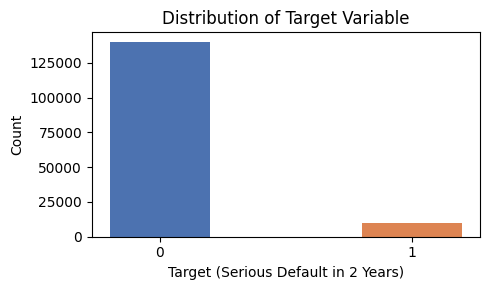

In [ ]:
import matplotlib.pyplot as plt

counts = df_raw['Target'].value_counts().sort_index()

plt.figure(figsize=(5, 3))

plt.bar(
    counts.index.astype(str),
    counts.values,
    color=['#4C72B0', '#DD8452'],
    width=0.4
)

plt.xlabel('Target (Serious Default in 2 Years)')
plt.ylabel('Count')
plt.title('Distribution of Target Variable')

plt.tight_layout()
plt.show()

**1.3 · Missing Values — Bar Chart**

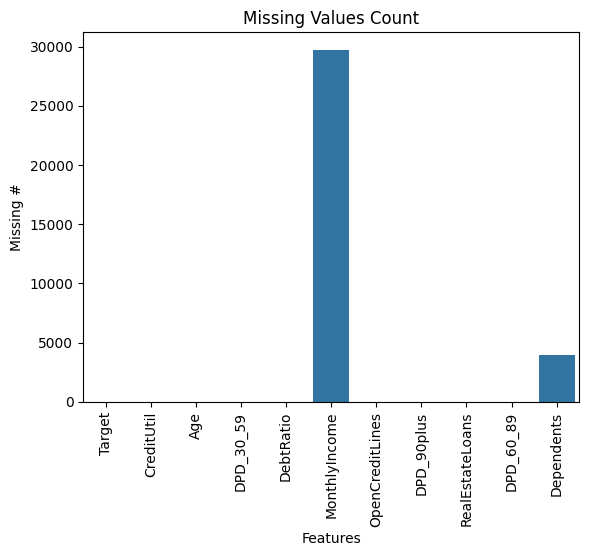

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(x=missing_table.index, y=missing_table['Missing #'])
plt.xlabel('Features')
plt.ylabel('Missing #')
plt.title('Missing Values Count')
plt.xticks(rotation=90)
plt.show()

**1.4 · Correlation Heatmap (Full Feature Matrix)**

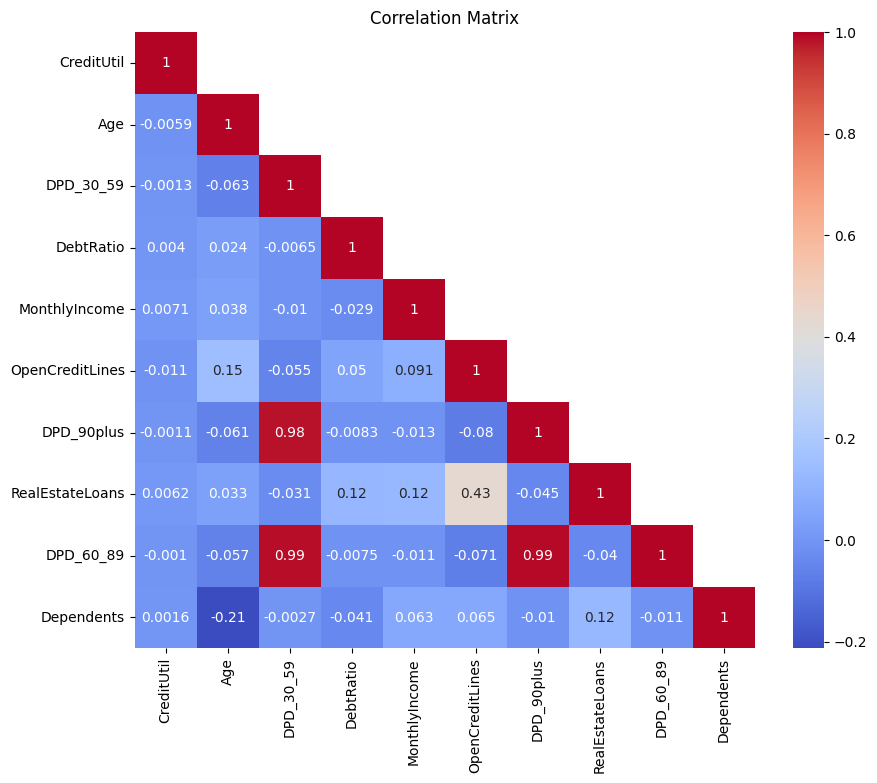

High correlations (|r| > 0.5):
  DPD_30_59  <->  DPD_90plus  :  r = 0.984
  DPD_30_59  <->  DPD_60_89  :  r = 0.987
  DPD_60_89  <->  DPD_90plus  :  r = 0.993


In [ ]:
import numpy as np

df_features_raw = df_raw.drop(columns=['Target'])
df_target_raw = df_raw['Target']

corr = df_features_raw.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, mask = mask, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

high = (corr.abs() > 0.5) & (corr.abs() < 1.0)
print("High correlations (|r| > 0.5):")
for c1 in corr.columns:
    for c2 in corr.columns:
        if c1 < c2 and high.loc[c1, c2]:
            print(f"  {c1}  <->  {c2}  :  r = {corr.loc[c1,c2]:.3f}")

**1.5 · Feature Type Checking (Numerical/Categorical)**

In [ ]:
from sklearn.compose import make_column_selector as selector

numerical_features = selector(dtype_exclude=object)(df_features_raw)
categorical_features = selector(dtype_include=object)(df_features_raw)

print(numerical_features)
print(categorical_features)

['CreditUtil', 'Age', 'DPD_30_59', 'DebtRatio', 'MonthlyIncome', 'OpenCreditLines', 'DPD_90plus', 'RealEstateLoans', 'DPD_60_89', 'Dependents']
[]


In [ ]:
df_features_raw.describe()

,CreditUtil,Age,DPD_30_59,DebtRatio,MonthlyIncome,OpenCreditLines,DPD_90plus,RealEstateLoans,DPD_60_89,Dependents
count,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


**1.6 · Feature Distributions (2×5 Histograms)**

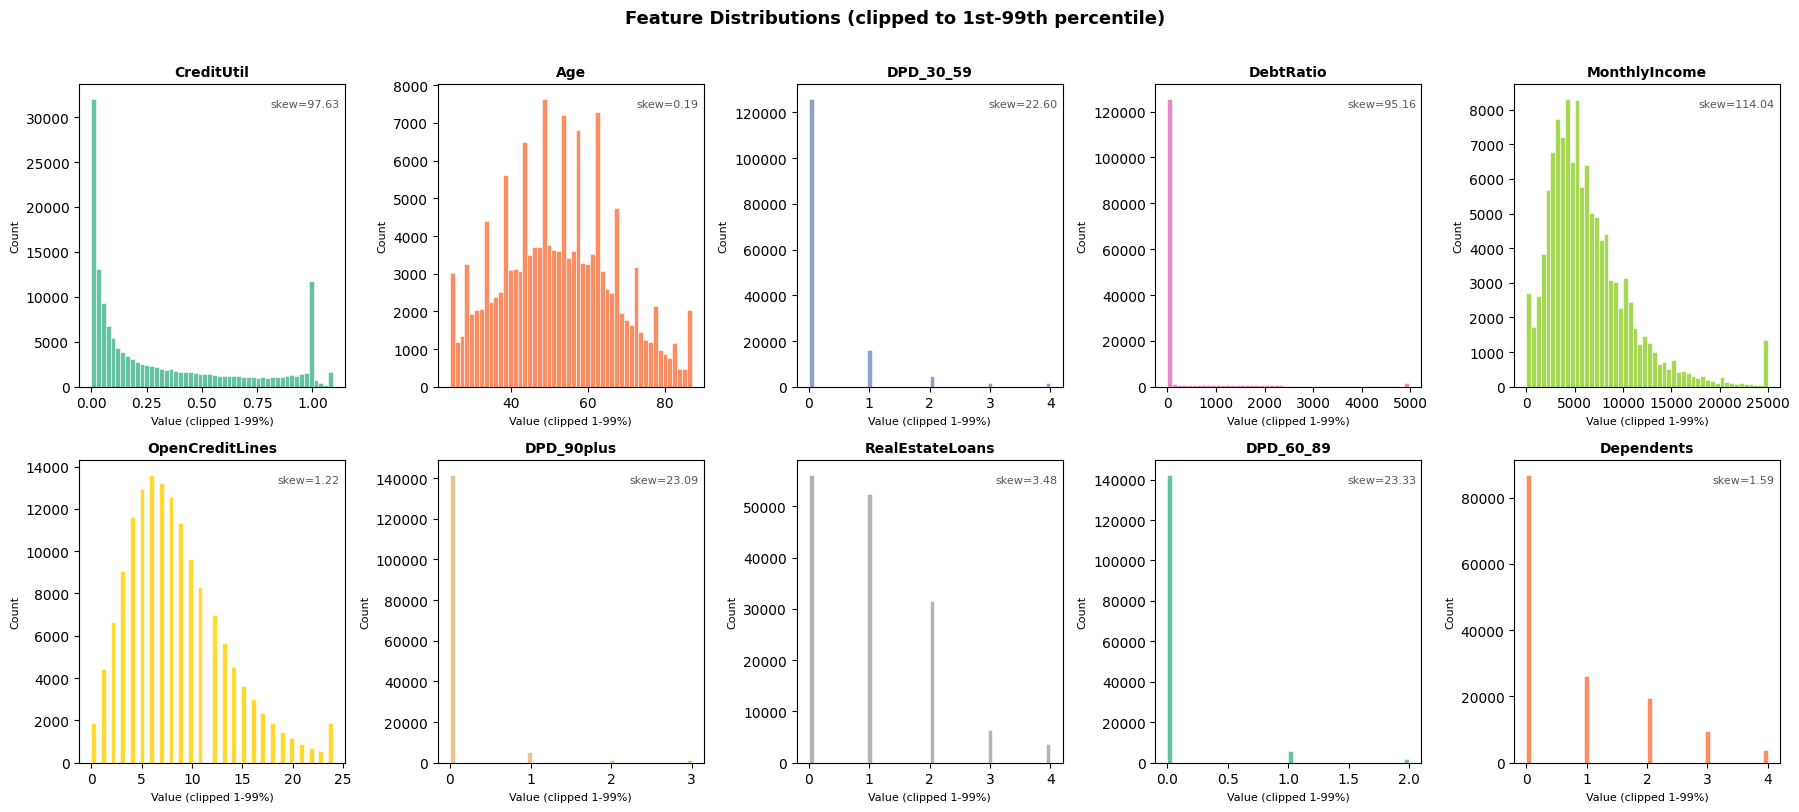

In [ ]:
feats = [c for c in df_raw.columns if c != 'Target']

palette = sns.color_palette('Set2')
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(feats):
    data = df_features_raw[col]
    p1, p99 = data.quantile(0.01), data.quantile(0.99)
    data_clip = data.clip(p1, p99)
    axes[i].hist(data_clip.dropna(), bins=50, color=palette[i % len(palette)],
                 edgecolor='white', linewidth=0.4)
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Value (clipped 1-99%)', fontsize=8)
    axes[i].set_ylabel('Count', fontsize=8)
    sk = data.skew()
    axes[i].text(0.98, 0.95, f'skew={sk:.2f}', transform=axes[i].transAxes,
                 ha='right', va='top', fontsize=8, color='#555')

fig.suptitle('Feature Distributions (clipped to 1st-99th percentile)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()

**1.7 · Features boxplots by Class**

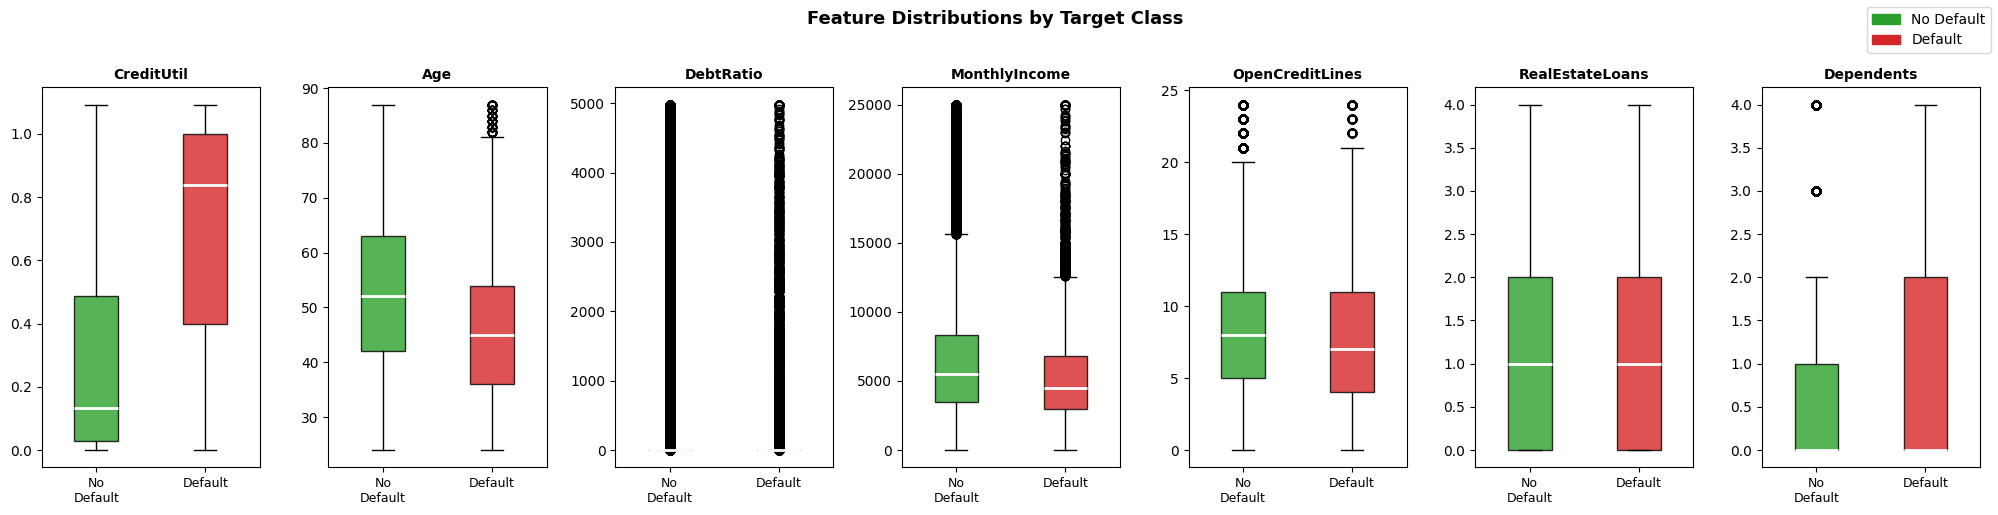

In [ ]:
import matplotlib.patches as mpatches

# Define the color variables
TEAL = '#2ca02c' # standard soft green/teal
RED = '#d62728'  # standard soft red

feats_box = ['CreditUtil', 'Age', 'DebtRatio', 'MonthlyIncome',
             'OpenCreditLines', 'RealEstateLoans', 'Dependents']
fig, axes = plt.subplots(1, len(feats_box), figsize=(20, 5))

for i, col in enumerate(feats_box):
    sub = df_raw[[col, 'Target']].dropna().copy()
    p1, p99 = sub[col].quantile(0.01), sub[col].quantile(0.99)
    sub[col] = sub[col].clip(p1, p99)
    data0 = sub[sub['Target'] == 0][col]
    data1 = sub[sub['Target'] == 1][col]
    bp = axes[i].boxplot([data0, data1], patch_artist=True, widths=0.4,
                          medianprops={'color': 'white', 'linewidth': 2})
    for patch, color in zip(bp['boxes'], [TEAL, RED]):
        patch.set_facecolor(color); patch.set_alpha(0.8)
    axes[i].set_xticklabels(['No\nDefault', 'Default'], fontsize=9)
    axes[i].set_title(col, fontsize=10, fontweight='bold')

legend_patches = [mpatches.Patch(color=TEAL, label='No Default'),
                  mpatches.Patch(color=RED, label='Default')]
fig.legend(handles=legend_patches, loc='upper right', fontsize=10)
fig.suptitle('Feature Distributions by Target Class',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**1.8 · Delinquency Rate vs Key Risk Drivers (2×2 Subplots)**

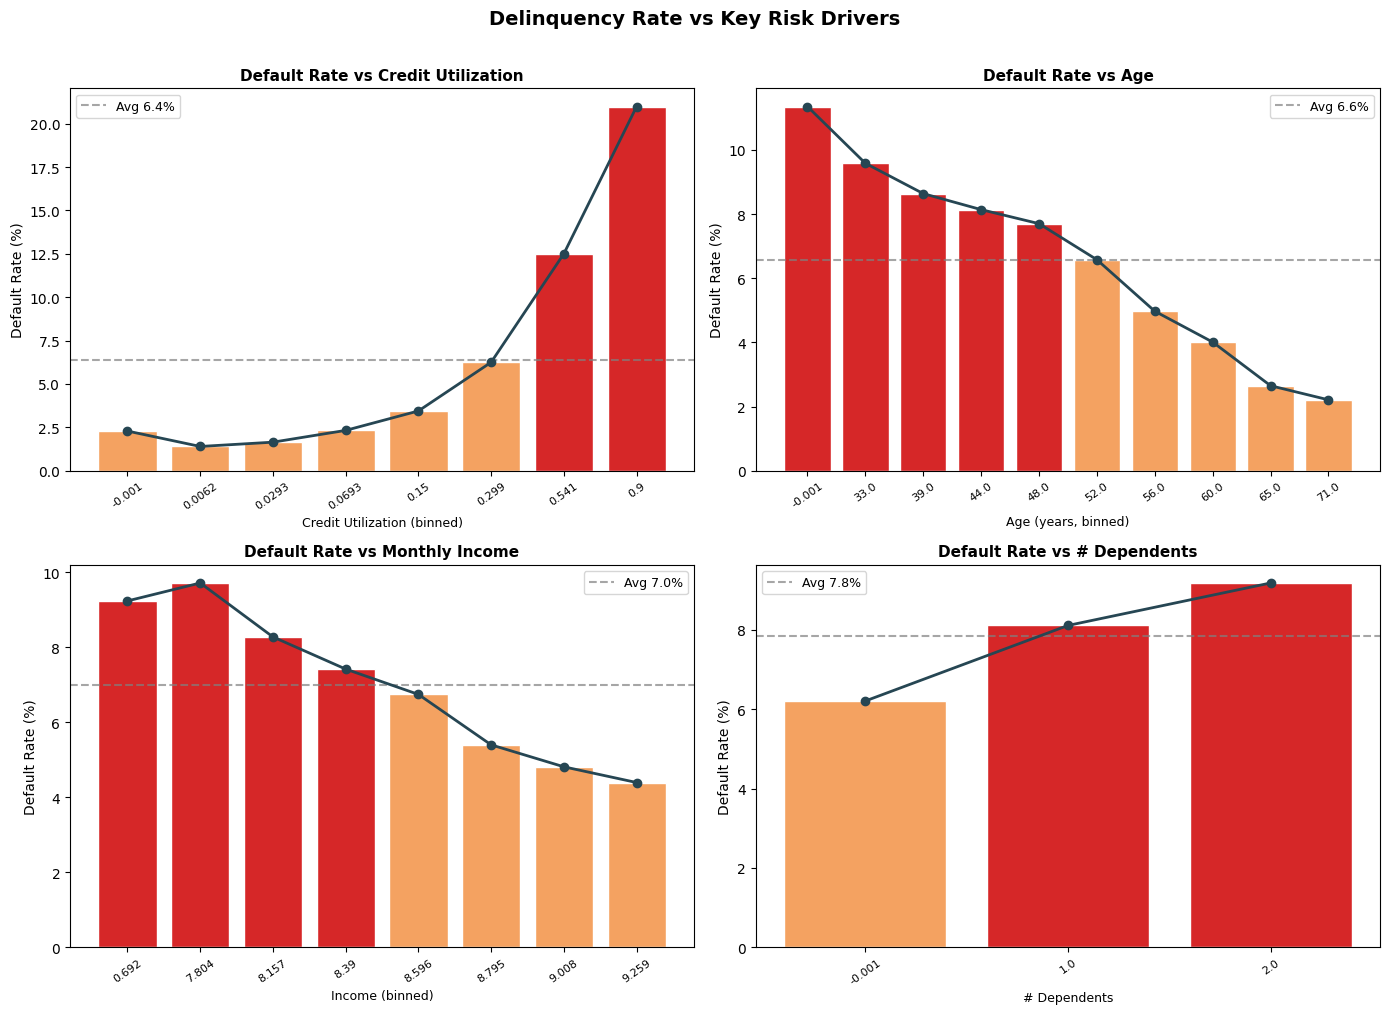

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

def delinquency_rate_plot(ax, col, n_bins, title, xlabel, log_x=False):
    sub = df_raw[[col, 'Target']].dropna().copy()
    p99 = sub[col].quantile(0.99)
    sub = sub[sub[col] <= p99]
    if log_x:
        sub = sub[sub[col] > 0].copy()
        sub[col] = np.log1p(sub[col])
    sub['bin'] = pd.qcut(sub[col], q=n_bins, duplicates='drop')
    grouped = sub.groupby('bin', observed=True)['Target']
    rates  = grouped.mean() * 100
    counts = grouped.count()
    mids   = range(len(rates))
    bars = ax.bar(mids, rates.values,
                  color=[RED if r > rates.mean() else '#F4A261' for r in rates.values],
                  edgecolor='white', linewidth=1)
    ax.plot(mids, rates.values, 'o-', color='#264653', linewidth=2, markersize=6, zorder=5)
    ax.axhline(rates.mean(), linestyle='--', color='gray', alpha=0.7,
               label=f'Avg {rates.mean():.1f}%')
    labels = [str(b).replace('(', '').replace(']', '').split(',')[0][:6]
              for b in rates.index]
    ax.set_xticks(mids); ax.set_xticklabels(labels, rotation=35, fontsize=8)
    ax.set_ylabel('Default Rate (%)', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=9)
    ax.legend(fontsize=9)

delinquency_rate_plot(axes[0, 0], 'CreditUtil',  8,
    'Default Rate vs Credit Utilization', 'Credit Utilization (binned)')
delinquency_rate_plot(axes[0, 1], 'Age', 10,
    'Default Rate vs Age', 'Age (years, binned)')
delinquency_rate_plot(axes[1, 0], 'MonthlyIncome', 8,
    'Default Rate vs Monthly Income', 'Income (binned)', log_x=True)
delinquency_rate_plot(axes[1, 1], 'Dependents', 6,
    'Default Rate vs # Dependents', '# Dependents')

fig.suptitle('Delinquency Rate vs Key Risk Drivers',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**1.9 · DPD Inter-Correlation + Feature Predictive Strength**

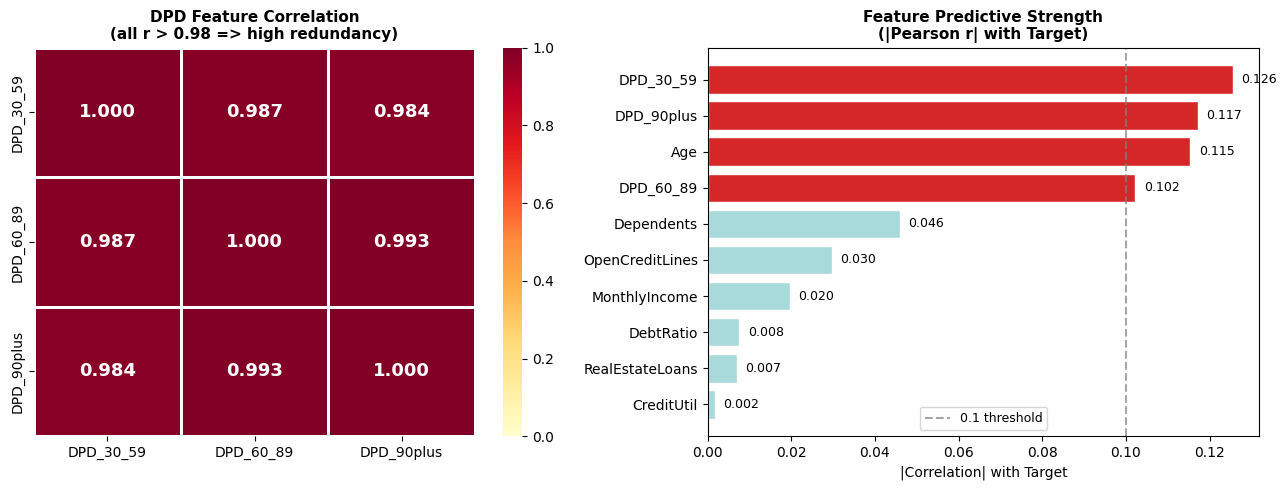

DPD inter-correlations (should all be > 0.98):
            DPD_30_59  DPD_60_89  DPD_90plus
DPD_30_59       1.000      0.987       0.984
DPD_60_89       0.987      1.000       0.993
DPD_90plus      0.984      0.993       1.000

Key insight: DPD_30_59 / DPD_60_89 / DPD_90plus are highly correlated
=> Drop DPD_60_89 and DPD_90plus; keep DPD_30_59 to reduce multicollinearity.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# DPD correlations
dpd_cols = ['DPD_30_59', 'DPD_60_89', 'DPD_90plus']
dpd_corr = df_raw[dpd_cols].corr()
sns.heatmap(dpd_corr, annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=1, ax=axes[0], vmin=0, vmax=1,
            annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title('DPD Feature Correlation\n(all r > 0.98 => high redundancy)',
                  fontsize=11, fontweight='bold')

# Feature predictive strength (|r| with Target)
numeric_feats = [c for c in df_raw.columns if c != 'Target']
corr_with_target = df_raw[numeric_feats + ['Target']].corr()['Target'].drop('Target')
corr_with_target = corr_with_target.abs().sort_values(ascending=True)
colors_c = [RED if v > 0.1 else '#A8DADC' for v in corr_with_target.values]
axes[1].barh(corr_with_target.index, corr_with_target.values,
             color=colors_c, edgecolor='white')
axes[1].axvline(0.1, linestyle='--', color='gray', alpha=0.7, label='0.1 threshold')
axes[1].set_xlabel('|Correlation| with Target', fontsize=10)
axes[1].set_title('Feature Predictive Strength\n(|Pearson r| with Target)',
                  fontsize=11, fontweight='bold')
axes[1].legend(fontsize=9)
for i, (val, name) in enumerate(zip(corr_with_target.values, corr_with_target.index)):
    axes[1].text(val + 0.002, i, f'{val:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()
print("DPD inter-correlations (should all be > 0.98):")
print(dpd_corr.round(3))
print("\nKey insight: DPD_30_59 / DPD_60_89 / DPD_90plus are highly correlated")
print("=> Drop DPD_60_89 and DPD_90plus; keep DPD_30_59 to reduce multicollinearity.")

#**2 · Preprocessing Pipeline Comparison**


* Dividing dataset into 70/30 stratify train test split
* Clipping out outliers
* Removing Invalid Age

In [ ]:
df = df_raw.copy()

# 1. Remove invalid age
before = len(df)
df = df[df['Age'] > 0].reset_index(drop=True)
print(f"Removed {before - len(df)} record(s) with Age=0 => {len(df):,} remain")

# 2. Clip outliers (1-99th pct) for all numeric columns except Target
clip_cols = [c for c in df.columns if c != 'Target']
for col in clip_cols:
    p1, p99 = df[col].quantile(0.01), df[col].quantile(0.99)
    df[col] = df[col].clip(p1, p99)

X = df.drop(columns=['Target'])
y = df['Target']

# 70/30 stratified train/test split
SEED = 42

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)

print(f"\nTrain: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train default rate: {y_train.mean()*100:.2f}%")
print(f"Test  default rate: {y_test.mean()*100:.2f}%")

import joblib
import os

# Create project folder
drive_path = "/content/drive/MyDrive/"

os.makedirs(drive_path, exist_ok=True)

# Save datasets
joblib.dump(X_train, drive_path + "X_train.pkl")
joblib.dump(X_test, drive_path + "X_test.pkl")

# Also save target variables (useful for future evaluation)
joblib.dump(y_train, drive_path + "y_train.pkl")
joblib.dump(y_test, drive_path + "y_test.pkl")

print("All datasets saved successfully!")

Removed 1 record(s) with Age=0 => 149,999 remain

Train: (104999, 10)  |  Test: (45000, 10)
Train default rate: 6.68%
Test  default rate: 6.68%
All datasets saved successfully!


* Since Logistic Regression is a linear model, multicollinearity among
predictors can affect coefficient estimates and their interpretability.

* Therefore, to reduce potential multicollinearity among the DPD variables,
I retained DPD_30_59 and excluded the other DPD features when comparing
the different preprocessing pipelines.




**2.1 · Pipeline A — Median/Mode Imputation + StandardScaler using weighted class balance**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

results_dict = {}

income_col = ['MonthlyIncome']
dep_col    = ['Dependents']
other_cols = [c for c in X.columns if c not in ('MonthlyIncome', 'Dependents', 'DPD_60_89', 'DPD_90plus')]

preprocessor_A = ColumnTransformer([
    ('median_imp', SimpleImputer(strategy='median'),       income_col),
    ('mode_imp',   SimpleImputer(strategy='most_frequent'), dep_col),
    ('passthrough', 'passthrough',                          other_cols),
])

pipeline_A = Pipeline([
    ('imputer', preprocessor_A),
    ('scaler',  StandardScaler()),
    ('clf',     LogisticRegression(class_weight='balanced',
                                   max_iter=1000, random_state=SEED)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scores_A = cross_val_score(pipeline_A, X_train, y_train, cv=cv,
                           scoring='average_precision', n_jobs=-1)

results_dict['Pipeline A - Median/Mode Imputation + StandardScaler'] = scores_A

print(f"Pipeline A  Avg.Precision: {scores_A.mean():.4f} +/- {scores_A.std():.4f}")
print(f"Fold scores: {scores_A.round(4)}")

Pipeline A  Avg.Precision: 0.2951 +/- 0.0123
Fold scores: [0.3059 0.301  0.3055 0.2734 0.29  ]


**2.2 · Pipeline B — Median/Mode Imputation + MinMaxScaler using weighted class balance**

In [ ]:
from sklearn.preprocessing import MinMaxScaler

preprocessor_B = ColumnTransformer([
    ('mean_imp', SimpleImputer(strategy='mean'),       income_col),
    ('mode_imp',   SimpleImputer(strategy='most_frequent'), dep_col),
    ('passthrough', 'passthrough',                          other_cols),
])

pipeline_B = Pipeline([
    ('imputer', preprocessor_B),
    ('scaler',  MinMaxScaler()),
    ('clf',     LogisticRegression(class_weight='balanced',
                                   max_iter=1000, random_state=SEED)),
])

scores_B = cross_val_score(pipeline_B, X_train, y_train, cv=cv,
                           scoring='average_precision', n_jobs=-1)

results_dict['Pipeline B - Median/Mode Imputation + MinMaxScaler'] = scores_B

print(f"Pipeline B  Avg.Precision: {scores_B.mean():.4f} +/- {scores_B.std():.4f}")
print(f"Fold scores: {scores_B.round(4)}")

Pipeline B  Avg.Precision: 0.2949 +/- 0.0124
Fold scores: [0.3056 0.3009 0.3055 0.2729 0.2897]


**2.3 · Pipelin C — IterativeImputer + RobustScaler + SMOTEe**

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

preprocessor_C = ColumnTransformer([
    ('iterative_imp', IterativeImputer(
        estimator=BayesianRidge(),
        max_iter=10,
        random_state=SEED
    ), income_col + dep_col),

    ('passthrough', 'passthrough', other_cols),
])

pipeline_C = ImbPipeline([
    ('imputer', preprocessor_C),
    ('scaler', RobustScaler()),
    ('smote', SMOTE(random_state=SEED, k_neighbors=5)),
    ('clf', LogisticRegression(
        class_weight=None,
        max_iter=1000,
        random_state=SEED
    )),
])

scores_C = cross_val_score(pipeline_C, X_train, y_train, cv=cv,
                           scoring='average_precision', n_jobs=-1)

results_dict['Pipeline C - IterativeImputer + RobustScaler + SMOTE'] = scores_C

print(f"Pipeline C  Avg.Precision: {scores_C.mean():.4f} +/- {scores_C.std():.4f}")
print(f"Fold scores: {scores_C.round(4)}")


Pipeline C  Avg.Precision: 0.2947 +/- 0.0124
Fold scores: [0.306  0.3006 0.3045 0.2727 0.2899]


* We can use KNN too as imputer with 3/5 neighbors but due to limited computational resources we are not trying that





**Section 3 — Best Pipeline Evaluation (Pipeline A on 70/30 Test Split)**

In [ ]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_auc_score,
    average_precision_score, precision_score,
    recall_score, f1_score, accuracy_score
)

# Select the best pipeline based on mean cross-validation scores
best_scores = [scores_A.mean(), scores_B.mean(), scores_C.mean()]
best_idx   = np.argmax(best_scores)

best_pipe = [pipeline_A, pipeline_B, pipeline_C][best_idx]
best_name = ['A', 'B', 'C'][best_idx]

print(f"Fitting Pipeline {best_name} on training data ...")

# Fit the selected pipeline
best_pipe.fit(X_train, y_train)

# Predictions on training data
y_train_pred = best_pipe.predict(X_train)
y_train_prob_lr = best_pipe.predict_proba(X_train)[:, 1]

# Predictions on test data
y_test_pred = best_pipe.predict(X_test)
y_test_prob_lr = best_pipe.predict_proba(X_test)[:, 1]

Pipeline_A_results = {}

def evaluate_model(y_true, y_pred, y_prob, dataset_name):

    # Classification error
    error = 1 - accuracy_score(y_true, y_pred)

    # Classification metrics
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall    = recall_score(y_true, y_pred, zero_division=0)
    f1        = f1_score(y_true, y_pred, zero_division=0)
    auc       = roc_auc_score(y_true, y_prob)
    ap        = average_precision_score(y_true, y_prob)

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    # Store results
    Pipeline_A_results[dataset_name] = {
        'Classification Error': error,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'Average Precision': ap,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Confusion Matrix': cm
    }

    return cm

cm_train = evaluate_model(
    y_train, y_train_pred, y_train_prob_lr, "TRAINING"
)

# Evaluate test data
cm_test = evaluate_model(
    y_test, y_test_pred, y_test_prob_lr, "TEST"
)


Fitting Pipeline A on training data ...


In [ ]:
print("========== PIPELINE A RESULTS ==========")

print("\n--- TRAINING RESULTS ---")
print(f"ROC-AUC:             {Pipeline_A_results['TRAINING']['ROC-AUC']:.4f}")
print(f"Precision:           {Pipeline_A_results['TRAINING']['Precision']:.4f}")
print(f"Recall:              {Pipeline_A_results['TRAINING']['Recall']:.4f}")
print(f"F1-Score:            {Pipeline_A_results['TRAINING']['F1-Score']:.4f}")
print(f"Average Precision:   {Pipeline_A_results['TRAINING']['Average Precision']:.4f}")
print(f"Classification Error:{Pipeline_A_results['TRAINING']['Classification Error']:.4f}")

print("\n--- TEST RESULTS ---")
print(f"ROC-AUC:             {Pipeline_A_results['TEST']['ROC-AUC']:.4f}")
print(f"Precision:           {Pipeline_A_results['TEST']['Precision']:.4f}")
print(f"Recall:              {Pipeline_A_results['TEST']['Recall']:.4f}")
print(f"F1-Score:            {Pipeline_A_results['TEST']['F1-Score']:.4f}")
print(f"Average Precision:   {Pipeline_A_results['TEST']['Average Precision']:.4f}")
print(f"Classification Error:{Pipeline_A_results['TEST']['Classification Error']:.4f}")

========== PIPELINE A RESULTS ==========

--- TRAINING RESULTS ---
ROC-AUC:             0.8267
Precision:           0.1838
Recall:              0.7442
F1-Score:            0.2948
Average Precision:   0.2949
Classification Error:0.2380

--- TEST RESULTS ---
ROC-AUC:             0.8298
Precision:           0.1852
Recall:              0.7400
F1-Score:            0.2963
Average Precision:   0.3111
Classification Error:0.2350


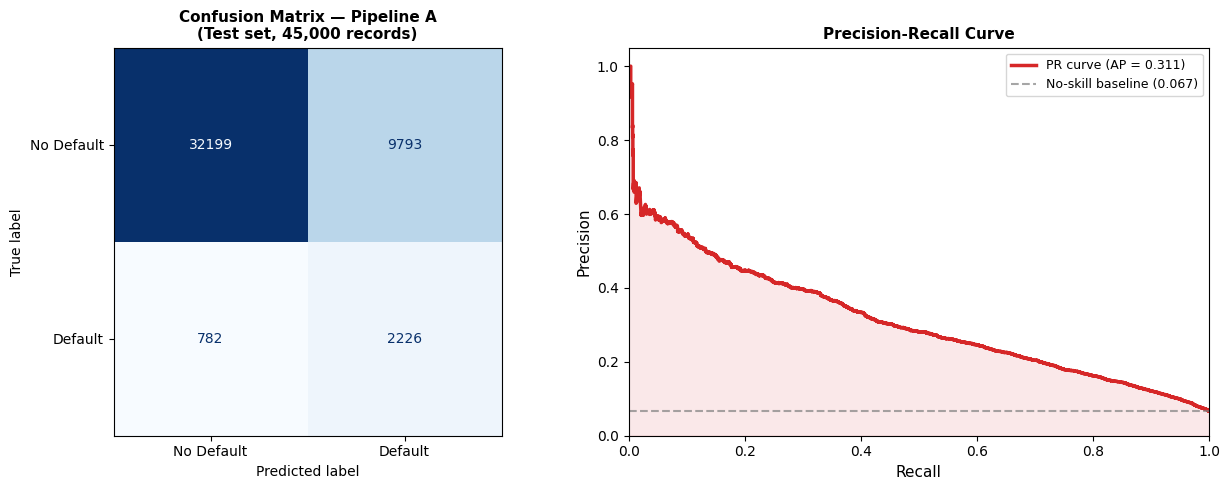

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Test Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=['No Default', 'Default']
)

disp.plot(ax=axes[0], colorbar=False, cmap='Blues')

axes[0].set_title(
    f'Confusion Matrix — Pipeline {best_name}\n'
    f'(Test set, {len(y_test):,} records)',
    fontsize=11, fontweight='bold'
)

# 2. Precision-Recall Curve
precision, recall, _ = precision_recall_curve(
    y_test, y_test_prob_lr
)

ap = average_precision_score(y_test, y_test_prob_lr)

axes[1].plot(
    recall, precision,
    color=RED, linewidth=2.5,
    label=f'PR curve (AP = {ap:.3f})'
)

axes[1].fill_between(
    recall, precision,
    alpha=0.1, color=RED
)

# No-skill baseline
no_skill = y_test.mean()

axes[1].axhline(
    no_skill, linestyle='--',
    color='gray', alpha=0.7,
    label=f'No-skill baseline ({no_skill:.3f})'
)

axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title(
    'Precision-Recall Curve',
    fontsize=11, fontweight='bold'
)

axes[1].legend(fontsize=9)
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.05])

plt.tight_layout()
plt.show()

#**Section 4 — Feature Importance**

**Random Forest (200 trees) trained on Preprocessing A and SMOTe**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from imblearn.over_sampling import SMOTE


def run_rf_experiment(
    X_train,
    X_test,
    y_train,
    y_test,
    other_cols,
    experiment_name,
    seed=42,
    plot_importance=True
):
    # Define columns
    income_col = ['MonthlyIncome']
    dep_col = ['Dependents']

    # Preprocessing
    preprocessor = ColumnTransformer([
        ('median_imp', SimpleImputer(strategy='median'), income_col),
        ('mode_imp', SimpleImputer(strategy='most_frequent'), dep_col),
        ('passthrough', 'passthrough', other_cols)
    ])

    X_train_prep = preprocessor.fit_transform(X_train)
    X_test_prep = preprocessor.transform(X_test)

    # SMOTE
    sm = SMOTE(
        random_state=seed,
        k_neighbors=5
    )

    X_res, y_res = sm.fit_resample(X_train_prep, y_train)

    # Random Forest
    rf = RandomForestClassifier(
        n_estimators=200,
        class_weight=None,
        random_state=seed,
        n_jobs=-1
    )

    rf.fit(X_res, y_res)

    # Predictions
    y_prob = rf.predict_proba(X_test_prep)[:, 1]

    # Evaluation
    rf_ap = average_precision_score(y_test, y_prob)
    rf_auc = roc_auc_score(y_test, y_prob)

    print(f"\n{'='*45}")
    print(f"Experiment: {experiment_name}")
    print(f"{'='*45}")
    print(f"Random Forest Test AP:      {rf_ap:.4f}")
    print(f"Random Forest Test ROC-AUC: {rf_auc:.4f}")

    # Feature importance
    feature_names = preprocessor.get_feature_names_out()

    importances = pd.Series(
        rf.feature_importances_,
        index=feature_names
    ).sort_values()

    if plot_importance:
        colors_fi = [
            RED if imp > importances.mean() else TEAL
            for imp in importances.values
        ]

        fig, ax = plt.subplots(figsize=(9, 5))

        bars = ax.barh(
            importances.index,
            importances.values,
            color=colors_fi,
            edgecolor='white',
            linewidth=1
        )

        ax.axvline(
            importances.mean(),
            linestyle='--',
            color='gray',
            alpha=0.7,
            label='Mean importance'
        )

        for bar, val in zip(bars, importances.values):
            ax.text(
                val + 0.001,
                bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}',
                va='center',
                fontsize=9
            )

        ax.set_xlabel('Mean Decrease in Impurity')
        ax.set_title(
            f'Feature Importance — {experiment_name}\n'
            '(Median/Mode Imputation + Random Forest)'
        )

        ax.legend()
        plt.tight_layout()
        plt.show()

    # Print importance ranking
    print("\nFeature importance ranking:")
    for feat, imp in importances.sort_values(ascending=False).items():
        print(f"  {feat:25s}: {imp:.4f}")

    # Return results
    return {
        'Experiment': experiment_name,
        'ROC-AUC': rf_auc,
        'AP': rf_ap,
        'Model': rf,
        'Preprocessor': preprocessor,
        'Importances': importances
    }


* DPD_30_59 appeared as the most important feature in the Random
Forest model, we will investigate whether including the remaining DPD
features improves predictive performance.

* Unlike Logistic Regression, Random Forest is generally robust to multicollinearity. Therefore, we
will train and compare models using both the reduced feature set and
the full feature set, evaluating their test ROC-AUC and Average
Precision scores to determine whether retaining all DPD features
provides any meaningful improvement.


Experiment: Reduced Features
Random Forest Test AP:      0.2649
Random Forest Test ROC-AUC: 0.8081


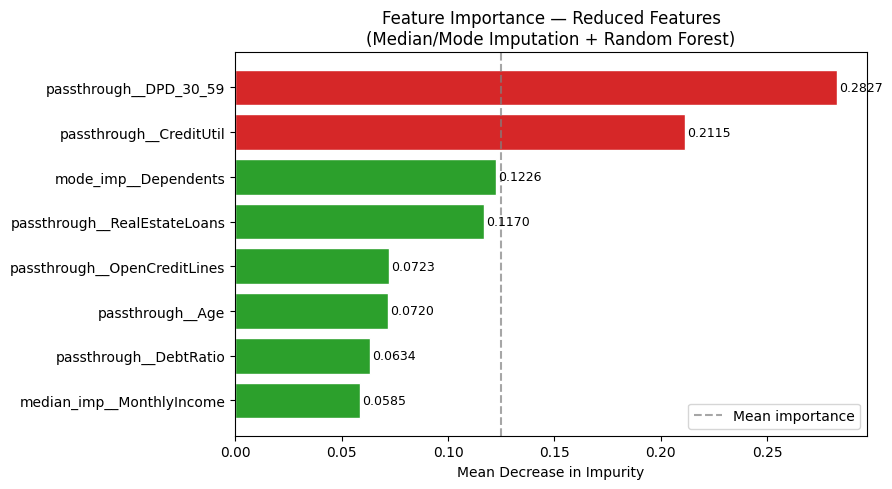


Feature importance ranking:
  passthrough__DPD_30_59   : 0.2827
  passthrough__CreditUtil  : 0.2115
  mode_imp__Dependents     : 0.1226
  passthrough__RealEstateLoans: 0.1170
  passthrough__OpenCreditLines: 0.0723
  passthrough__Age         : 0.0720
  passthrough__DebtRatio   : 0.0634
  median_imp__MonthlyIncome: 0.0585

Experiment: All Features
Random Forest Test AP:      0.3469
Random Forest Test ROC-AUC: 0.8408


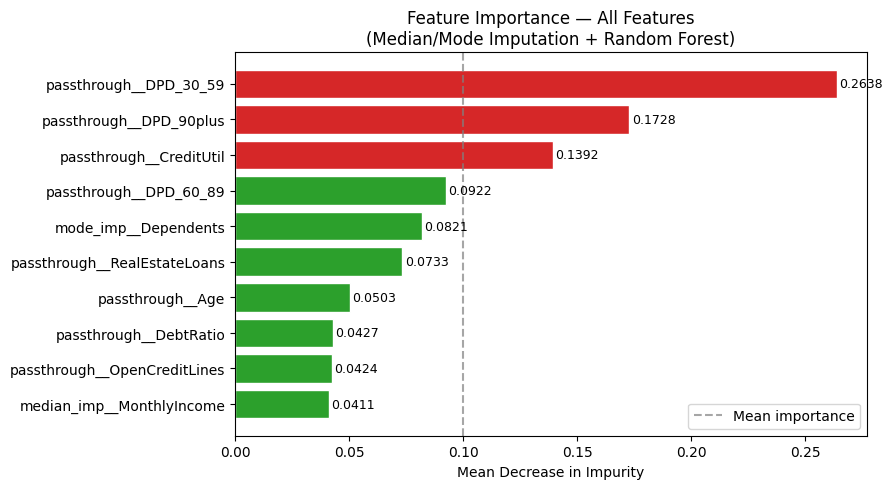


Feature importance ranking:
  passthrough__DPD_30_59   : 0.2638
  passthrough__DPD_90plus  : 0.1728
  passthrough__CreditUtil  : 0.1392
  passthrough__DPD_60_89   : 0.0922
  mode_imp__Dependents     : 0.0821
  passthrough__RealEstateLoans: 0.0733
  passthrough__Age         : 0.0503
  passthrough__DebtRatio   : 0.0427
  passthrough__OpenCreditLines: 0.0424
  median_imp__MonthlyIncome: 0.0411


In [ ]:
other_cols_1 = [c for c in X.columns if c not in ('MonthlyIncome', 'Dependents', 'DPD_60_89', 'DPD_90plus')]
other_cols_2 = [c for c in X.columns if c not in ('MonthlyIncome', 'Dependents')]

experiments = [
    (other_cols_1, 'Reduced Features'),
    (other_cols_2, 'All Features'),
]

results = []

for cols, name in experiments:

    result = run_rf_experiment(
        X_train=X_train,
        X_test=X_test,
        y_train=y_train,
        y_test=y_test,
        other_cols=cols,
        experiment_name=name,
        seed=SEED,
        plot_importance=True
    )

    results.append(result)


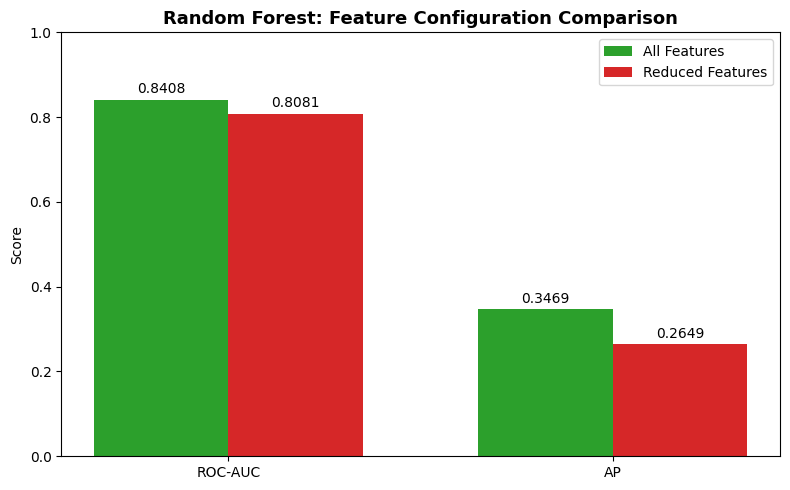

In [ ]:
results_df = pd.DataFrame([
    {
        'Experiment': r['Experiment'],
        'ROC-AUC': r['ROC-AUC'],
        'AP': r['AP']
    }
    for r in results
])

# Arrange metrics on X-axis
metrics = ['ROC-AUC', 'AP']

all_features = results_df.set_index('Experiment').loc[
    'All Features', metrics
].values

reduced_features = results_df.set_index('Experiment').loc[
    'Reduced Features', metrics
].values

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width/2,
    all_features,
    width,
    label='All Features',
    color=TEAL
)

bars2 = ax.bar(
    x + width/2,
    reduced_features,
    width,
    label='Reduced Features',
    color=RED
)

# Value labels
for bars in [bars1, bars2]:
    for bar in bars:
        val = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            val + 0.015,
            f'{val:.4f}',
            ha='center',
            fontsize=10
        )

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel('Score')
ax.set_ylim(0, 1)

ax.set_title(
    'Random Forest: Feature Configuration Comparison',
    fontsize=13,
    fontweight='bold'
)

ax.legend()
plt.tight_layout()
plt.show()


* Since the model trained using all features achieved better test ROC-AUC
and Average Precision scores than the reduced-feature model, we will
retain all features, including the remaining DPD variables, for further
model development.

#**Section 5 - Model Tuning and Selection**

**5.1 - Tuning of Random Forest Model with Average Precision Scoring**

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from scipy.stats import randint

# Preprocessing
other_cols = [c for c in X.columns
              if c not in ('MonthlyIncome', 'Dependents')]

preprocessor = ColumnTransformer([
    ('median_imp', SimpleImputer(strategy='median'), income_col),
    ('mode_imp', SimpleImputer(strategy='most_frequent'), dep_col),
    ('passthrough', 'passthrough', other_cols)
])

# Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=SEED, k_neighbors=5)),
    ('rf', RandomForestClassifier(
        random_state=SEED,
        n_jobs=1
    ))
])

# Hyperparameter search space
param_dist = {
    'rf__n_estimators': [100, 200, 300, 400],

    'rf__max_depth': [10, 15, 20, 25, 30],

    'rf__min_samples_split': [2, 5, 10],

    'rf__min_samples_leaf': [2, 4, 6, 8],

    'rf__max_features': ['sqrt', 'log2'],

    'rf__class_weight': [None, 'balanced']
}

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

rf_random = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    scoring='average_precision',
    cv=3,
    verbose=2,
    random_state=SEED,
    n_jobs=-1,
    return_train_score=True
)


# Fit on training data
rf_random.fit(X_train, y_train)

# Best parameters and score
print("Best Parameters:")
print(rf_random.best_params_)

print(f"\nBest CV AP: {rf_random.best_score_:.4f}")

# Best model
best_rf = rf_random.best_estimator_

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'rf__n_estimators': 300, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 8, 'rf__max_features': 'log2', 'rf__max_depth': 10, 'rf__class_weight': None}

Best CV AP: 0.3742


**5.2 - Evaluation of Tuned Random Forest Model**

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
# Predictions
y_test_pred_rf = best_rf.predict(X_test)
y_test_prob_rf = best_rf.predict_proba(X_test)[:, 1]

# Evaluation
rf_test_auc = roc_auc_score(y_test, y_test_prob_rf)
rf_test_ap = average_precision_score(y_test, y_test_prob_rf)

print(f"Test ROC-AUC: {rf_test_auc:.4f}")
print(f"Test Average Precision: {rf_test_ap:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))

results_dict['Random Forest'] = {
    'Model': best_rf,
    'ROC-AUC': rf_test_auc,
    'AP': rf_test_ap,
    'Classification Report': classification_report(y_test, y_test_pred_rf),
    'Confusion Matrix': confusion_matrix(y_test, y_test_pred_rf)
}


Test ROC-AUC: 0.8600
Test Average Precision: 0.3774

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     41992
           1       0.43      0.42      0.43      3008

    accuracy                           0.92     45000
   macro avg       0.70      0.69      0.69     45000
weighted avg       0.92      0.92      0.92     45000


Confusion Matrix:
[[40343  1649]
 [ 1740  1268]]


**5.3 - Fitting XGBoost Untuned Model**

In [ ]:
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from scipy.stats import randint, uniform

In [ ]:
# Untuned XGBoost pipeline
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),

    ('smote', SMOTE(
        random_state=SEED,
        k_neighbors=5
    )),

    ('xgb', XGBClassifier(
        objective='binary:logistic',
        eval_metric='aucpr',
        random_state=SEED,
        n_jobs=2,
        tree_method='hist'
    ))
])

# Fit model
print("Training Untuned XGBoost...")

xgb_pipeline.fit(X_train, y_train)

# Predictions
y_train_pred_xgb = xgb_pipeline.predict(X_train)
y_train_prob_xgb = xgb_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_xgb = xgb_pipeline.predict(X_test)
y_test_prob_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

Training Untuned XGBoost...


**5.4 - Evaluating XGBoost Untuned Model**

In [ ]:
def evaluate_xgb(y_true, y_pred, y_prob, dataset_name):

    error = 1 - accuracy_score(y_true, y_pred)

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    auc = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    print(f"\n{'=' * 45}")
    print(f"{dataset_name} RESULTS")
    print(f"{'=' * 45}")

    print(f"Classification Error : {error:.4f}")
    print(f"Precision             : {precision:.4f}")
    print(f"Recall                : {recall:.4f}")
    print(f"F1-Score              : {f1:.4f}")
    print(f"ROC-AUC               : {auc:.4f}")
    print(f"Average Precision     : {ap:.4f}")

    print("\nConfusion Matrix:")
    print(f"TN = {tn:,}   FP = {fp:,}")
    print(f"FN = {fn:,}   TP = {tp:,}")

    return cm


cm_train_xgb = evaluate_xgb(
    y_train, y_train_pred_xgb,
    y_train_prob_xgb, "UNTUNED XGBOOST - TRAIN"
)

cm_test_xgb = evaluate_xgb(
    y_test, y_test_pred_xgb,
    y_test_prob_xgb, "UNTUNED XGBOOST - TEST"
)


UNTUNED XGBOOST - TRAIN RESULTS
Classification Error : 0.0542
Precision             : 0.7377
Recall                : 0.2938
F1-Score              : 0.4203
ROC-AUC               : 0.9046
Average Precision     : 0.5388

Confusion Matrix:
TN = 97,248   FP = 733
FN = 4,956   TP = 2,062

UNTUNED XGBOOST - TEST RESULTS
Classification Error : 0.0651
Precision             : 0.5354
Recall                : 0.1988
F1-Score              : 0.2899
ROC-AUC               : 0.8561
Average Precision     : 0.3702

Confusion Matrix:
TN = 41,473   FP = 519
FN = 2,410   TP = 598


In [ ]:
results_dict['Untuned XGBoost'] = {
    'Model': xgb_pipeline,
    'Test': {
        'Precision': precision_score(y_test, y_test_pred_xgb),
        'Recall': recall_score(y_test, y_test_pred_xgb),
        'F1': f1_score(y_test, y_test_pred_xgb),
        'ROC-AUC': roc_auc_score(y_test, y_test_prob_xgb),
        'AP': average_precision_score(y_test, y_test_prob_xgb),
        'Confusion Matrix': cm_test_xgb
    }
}

**5.5 - Fitting Tuned XGBoost Model**

In [ ]:
param_dist_xgb = {

    'xgb__n_estimators': [100, 200, 300, 400],

    'xgb__max_depth': [3, 4, 5, 6],

    'xgb__learning_rate': [0.01, 0.03, 0.05, 0.1],

    'xgb__min_child_weight': [1, 3, 5, 7],

    'xgb__subsample': [0.7, 0.8, 0.9, 1.0],

    'xgb__colsample_bytree': [0.7, 0.8, 0.9, 1.0],

    'xgb__gamma': [0, 0.1, 0.3, 0.5],

    'xgb__reg_lambda': [1, 2, 5, 10]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

xgb_random = RandomizedSearchCV(
    estimator=xgb_pipeline,

    param_distributions=param_dist_xgb,

    n_iter=15,

    scoring='average_precision',

    cv=cv,

    verbose=2,

    random_state=SEED,

    n_jobs=2,

    return_train_score=False
)

In [ ]:
print("Starting XGBoost Hyperparameter Tuning...")

xgb_random.fit(X_train, y_train)

print("\nBest Parameters:")
print(xgb_random.best_params_)

print(f"\nBest CV AP: {xgb_random.best_score_:.4f}")

# Best tuned pipeline
best_xgb = xgb_random.best_estimator_

Starting XGBoost Hyperparameter Tuning...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters:
{'xgb__subsample': 1.0, 'xgb__reg_lambda': 1, 'xgb__n_estimators': 400, 'xgb__min_child_weight': 5, 'xgb__max_depth': 4, 'xgb__learning_rate': 0.1, 'xgb__gamma': 0.5, 'xgb__colsample_bytree': 0.7}

Best CV AP: 0.3842


**5.6 - Evaluating XGBoost Tuned Model**

In [ ]:
# Training predictions
y_train_pred_tuned = best_xgb.predict(X_train)
y_train_prob_tuned = best_xgb.predict_proba(X_train)[:, 1]

# Test predictions
y_test_pred_tuned = best_xgb.predict(X_test)
y_test_prob_tuned = best_xgb.predict_proba(X_test)[:, 1]

# Evaluate
cm_train_tuned = evaluate_xgb(
    y_train, y_train_pred_tuned,
    y_train_prob_tuned, "TUNED XGBOOST - TRAIN"
)

cm_test_tuned = evaluate_xgb(
    y_test, y_test_pred_tuned,
    y_test_prob_tuned, "TUNED XGBOOST - TEST"
)


TUNED XGBOOST - TRAIN RESULTS
Classification Error : 0.0604
Precision             : 0.6306
Recall                : 0.2340
F1-Score              : 0.3413
ROC-AUC               : 0.8781
Average Precision     : 0.4393

Confusion Matrix:
TN = 97,019   FP = 962
FN = 5,376   TP = 1,642

TUNED XGBOOST - TEST RESULTS
Classification Error : 0.0636
Precision             : 0.5626
Recall                : 0.2151
F1-Score              : 0.3112
ROC-AUC               : 0.8643
Average Precision     : 0.3900

Confusion Matrix:
TN = 41,489   FP = 503
FN = 2,361   TP = 647


In [ ]:
results_dict['Tuned XGBoost'] = {
    'Model': best_xgb,
    'Test': {
        'Precision': precision_score(y_test, y_test_pred_tuned),
        'Recall': recall_score(y_test, y_test_pred_tuned),
        'F1': f1_score(y_test, y_test_pred_tuned),
        'ROC-AUC': roc_auc_score(y_test, y_test_prob_tuned),
        'AP': average_precision_score(y_test, y_test_prob_tuned),
        'Confusion Matrix': cm_test_tuned
    },
    'Classification Report': classification_report(
        y_test, y_test_pred_tuned
    )
}

**5.7 - Choosing weights for best XGBoost and best RF ensemble Model**

In [ ]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

xgb_oof = cross_val_predict(
    best_xgb,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

rf_oof = cross_val_predict(
    best_rf,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

In [ ]:
from sklearn.metrics import average_precision_score
import pandas as pd

weights_list = [
    [1, 1],
    [2, 1],
    [3, 1],
    [1, 2],
    [1, 3]
]

results = []

for w_xgb, w_rf in weights_list:

    ensemble_probs = (
        w_xgb * xgb_oof + w_rf * rf_oof
    ) / (w_xgb + w_rf)

    ap = average_precision_score(y_train, ensemble_probs)

    results.append({
        'Weights': [w_xgb, w_rf],
        'Average Precision': ap
    })

results_df = pd.DataFrame(results).sort_values(
    'Average Precision',
    ascending=False
).reset_index(drop=True)

print(results_df)

best_weights = tuple(results_df.iloc[0]['Weights'])

print("Best weights:", best_weights)

  Weights  Average Precision
0  [1, 1]           0.387872
1  [2, 1]           0.387863
2  [3, 1]           0.387224
3  [1, 2]           0.385958
4  [1, 3]           0.384345
Best weights: (1, 1)


**5.8 - Fitting ensemble Model with best weights**

In [ ]:
from sklearn.ensemble import VotingClassifier

best_ensemble = VotingClassifier(
    estimators=[
        ('xgb', best_xgb),
        ('rf', best_rf)
    ],
    voting='soft',
    weights=best_weights,
    n_jobs=1
)

best_ensemble.fit(X_train, y_train)

VotingClassifier(estimators=[('xgb',
                              Pipeline(steps=[('preprocessor',
                                               ColumnTransformer(transformers=[('median_imp',
                                                                                SimpleImputer(strategy='median'),
                                                                                ['MonthlyIncome']),
                                                                               ('mode_imp',
                                                                                SimpleImputer(strategy='most_frequent'),
                                                                                ['Dependents']),
                                                                               ('passthrough',
                                                                                'passthrough',
                                                                                ['CreditUtil',
                                                                                 'Age',
                                                                                 'DPD_30_59',
                                                                                 'DebtRatio',
                                                                                 'OpenCreditLines',
                                                                                 'DPD_90plus',
                                                                                 'RealEstateL...
                                                                                ['Dependents']),
                                                                               ('passthrough',
                                                                                'passthrough',
                                                                                ['CreditUtil',
                                                                                 'Age',
                                                                                 'DPD_30_59',
                                                                                 'DebtRatio',
                                                                                 'OpenCreditLines',
                                                                                 'DPD_90plus',
                                                                                 'RealEstateLoans',
                                                                                 'DPD_60_89'])])),
                                              ('smote', SMOTE(random_state=42)),
                                              ('rf',
                                               RandomForestClassifier(max_depth=10,
                                                                      max_features='log2',
                                                                      min_samples_leaf=8,
                                                                      n_estimators=300,
                                                                      n_jobs=1,
                                                                      random_state=42))]))],
                 n_jobs=1, voting='soft', weights=(1, 1))

In [ ]:
# Training predictions
y_train_probs = best_ensemble.predict_proba(X_train)[:, 1]
y_train_pred_05 = best_ensemble.predict(X_train)

# Test predictions
y_test_probs = best_ensemble.predict_proba(X_test)[:, 1]
y_test_pred_05 = best_ensemble.predict(X_test)

**5.10 - Evaluating Ensemble Model with best weights**

In [ ]:
# Store results
results_dict['Weighted Ensemble'] = {
    'Model': best_ensemble,

    'Train': {
        'Precision': precision_score(y_train, y_train_pred_05),
        'Recall': recall_score(y_train, y_train_pred_05),
        'F1': f1_score(y_train, y_train_pred_05),
        'ROC-AUC': roc_auc_score(y_train, y_train_probs),
        'AP': average_precision_score(y_train, y_train_probs),
        'Confusion Matrix': confusion_matrix(y_train, y_train_pred_05)
    },

    'Test': {
        'Precision': precision_score(y_test, y_test_pred_05),
        'Recall': recall_score(y_test, y_test_pred_05),
        'F1': f1_score(y_test, y_test_pred_05),
        'ROC-AUC': roc_auc_score(y_test, y_test_probs),
        'AP': average_precision_score(y_test, y_test_probs),
        'Confusion Matrix': confusion_matrix(y_test, y_test_pred_05)
    },

    'Classification Report': classification_report(
        y_test, y_test_pred_05
    )
}

In [ ]:
for dataset in ['Train', 'Test']:
    print(f"\n{'='*50}")
    print(f"WEIGHTED ENSEMBLE - {dataset.upper()}")
    print(f"{'='*50}")

    for metric, value in results_dict['Weighted Ensemble'][dataset].items():
        print(f"\n{metric}:")
        print(value)


WEIGHTED ENSEMBLE - TRAIN

Precision:
0.567030303030303

Recall:
0.33328583642063264

F1:
0.41981513057524905

ROC-AUC:
0.8768043541770065

AP:
0.4431251334439847

Confusion Matrix:
[[96195  1786]
 [ 4679  2339]]

WEIGHTED ENSEMBLE - TEST

Precision:
0.5227272727272727

Recall:
0.3058510638297872

F1:
0.3859060402684564

ROC-AUC:
0.864379633924699

AP:
0.39095878477583

Confusion Matrix:
[[41152   840]
 [ 2088   920]]


**5.11 - Choosing Threshold Probability based on F2 Score**

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

oof_ensemble_probs = (
    best_weights[0] * xgb_oof +
    best_weights[1] * rf_oof
) / sum(best_weights)

precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_ensemble_probs
)

# Calculate F2-score
beta = 2

f2_scores = (
    (1 + beta**2) * precision[:-1] * recall[:-1]
    / (beta**2 * precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f2_scores)
best_threshold = thresholds[best_idx]

print(f"Optimal Threshold: {best_threshold:.4f}")
print(f"OOF Precision: {precision[best_idx]:.4f}")
print(f"OOF Recall: {recall[best_idx]:.4f}")
print(f"OOF F2-Score: {f2_scores[best_idx]:.4f}")

Optimal Threshold: 0.1834
OOF Precision: 0.2451
OOF Recall: 0.7164
OOF F2-Score: 0.5175


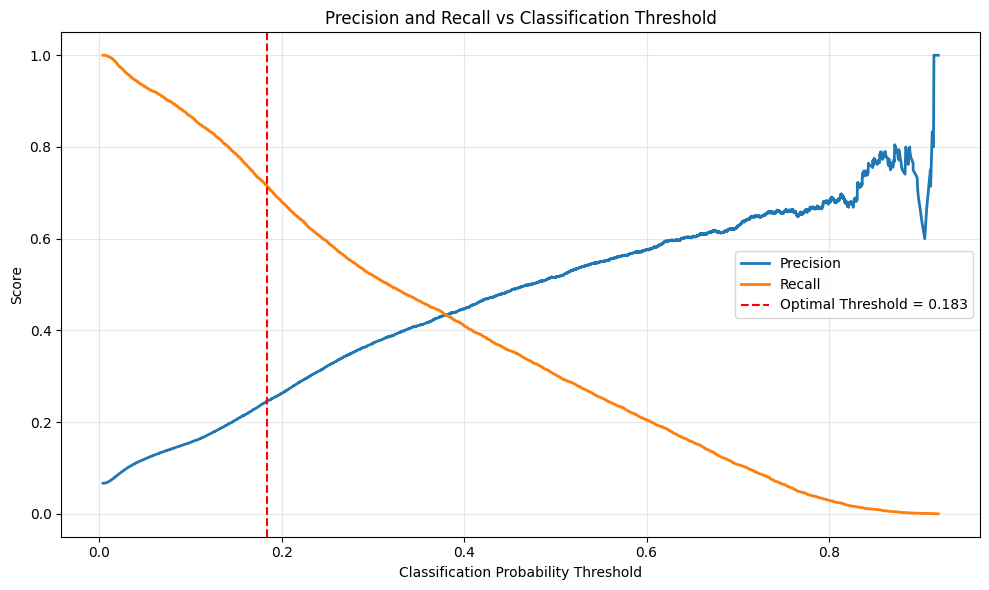

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
import numpy as np

# Calculate precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_ensemble_probs
)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision[:-1], label='Precision', linewidth=2)
plt.plot(thresholds, recall[:-1], label='Recall', linewidth=2)

# Mark optimal threshold
plt.axvline(
    best_threshold,
    color='red',
    linestyle='--',
    label=f'Optimal Threshold = {best_threshold:.3f}'
)

plt.xlabel('Classification Probability Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Classification Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

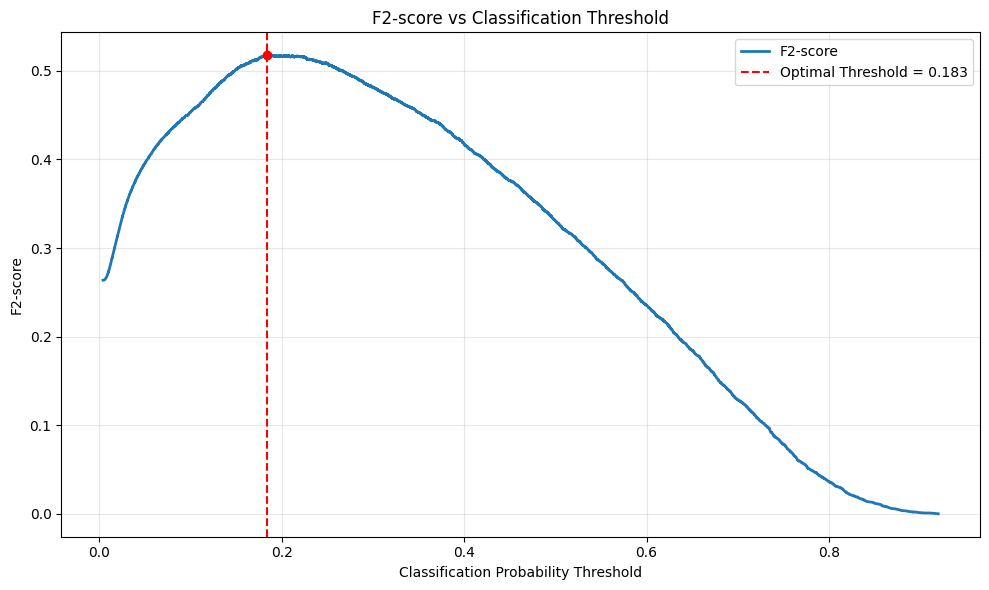

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    f2_scores,
    label='F2-score',
    linewidth=2
)

plt.axvline(
    best_threshold,
    color='red',
    linestyle='--',
    label=f'Optimal Threshold = {best_threshold:.3f}'
)

plt.scatter(
    best_threshold,
    f2_scores[best_idx],
    color='red',
    zorder=5
)

plt.xlabel('Classification Probability Threshold')
plt.ylabel('F2-score')
plt.title('F2-score vs Classification Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**5.12 - Evaluating Ensemble Model based on Threshold Probability**

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score
)

y_test_pred_opt = (y_test_probs >= best_threshold).astype(int)

print("=" * 45)
print("TUNED XGBOOST + RANDOM FOREST ENSEMBLE")
print("=" * 45)

print(f"Classification Error : {1 - accuracy_score(y_test, y_test_pred_opt):.4f}")
print(f"Precision             : {precision_score(y_test, y_test_pred_opt):.4f}")
print(f"Recall                : {recall_score(y_test, y_test_pred_opt):.4f}")
print(f"F1-Score              : {f1_score(y_test, y_test_pred_opt):.4f}")
print(f"ROC-AUC               : {roc_auc_score(y_test, y_test_probs):.4f}")
print(f"Average Precision     : {average_precision_score(y_test, y_test_probs):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_opt))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_opt))

TUNED XGBOOST + RANDOM FOREST ENSEMBLE
Classification Error : 0.1654
Precision             : 0.2473
Recall                : 0.7211
F1-Score              : 0.3683
ROC-AUC               : 0.8644
Average Precision     : 0.3910

Confusion Matrix:
[[35390  6602]
 [  839  2169]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.84      0.90     41992
           1       0.25      0.72      0.37      3008

    accuracy                           0.83     45000
   macro avg       0.61      0.78      0.64     45000
weighted avg       0.93      0.83      0.87     45000



In [ ]:
results_dict['Weighted Ensemble (Optimized Threshold)'] = {
    'Model': best_ensemble,
    'Threshold': best_threshold,
    'Test': {
        'Classification Error': 1 - accuracy_score(y_test, y_test_pred_opt),
        'Accuracy': accuracy_score(y_test, y_test_pred_opt),
        'Precision': precision_score(y_test, y_test_pred_opt),
        'Recall': recall_score(y_test, y_test_pred_opt),
        'F1': f1_score(y_test, y_test_pred_opt),
        'ROC-AUC': roc_auc_score(y_test, y_test_probs),
        'AP': average_precision_score(y_test, y_test_probs),
        'Confusion Matrix': confusion_matrix(y_test, y_test_pred_opt)
    },
    'Classification Report': classification_report(
        y_test, y_test_pred_opt
    )
}

In [ ]:
joblib.dump({
    'model': best_ensemble,
    'threshold': best_threshold,
    'features': X_train.columns.tolist()
}, 'credit_risk_model.pkl')

['credit_risk_model.pkl']

In [ ]:
from google.colab import files

files.download('credit_risk_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#**Section 6 - Comparision of all models**

In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

# Change this to the actual key you used for the test dataset
# in Pipeline_A_results.
dataset_name = 'TEST'

# Logistic Regression - Pipeline A
lr = Pipeline_A_results[dataset_name]

# Random Forest
rf = results_dict['Random Forest']

# Extract test metrics from nested results
def get_test_metrics(model_name):
    test = results_dict[model_name]['Test']

    return {
        'ROC-AUC': test['ROC-AUC'],
        'Precision': test['Precision'],
        'Recall': test['Recall'],
        'F1': test['F1'],
        'AP': test['AP']
    }

# Construct comparison table
comparison = {
    'LR Baseline': {
        'ROC-AUC': lr['ROC-AUC'],
        'Precision': lr['Precision'],
        'Recall': lr['Recall'],
        'F1': lr['F1-Score'],
        'AP': lr['Average Precision']
    },

    'Tuned Random Forest': {
        'ROC-AUC': rf['ROC-AUC'],
        'Precision': precision_score(y_test, y_test_pred_rf),
        'Recall': recall_score(y_test, y_test_pred_rf),
        'F1': f1_score(y_test, y_test_pred_rf),
        'AP': rf['AP']
    },

    'Untuned XGBoost': get_test_metrics('Untuned XGBoost'),

    'Tuned XGBoost': get_test_metrics('Tuned XGBoost'),

    'Weighted Ensemble': get_test_metrics('Weighted Ensemble'),

    'Ensemble (Optimized Threshold)': {
        'ROC-AUC': results_dict[
            'Weighted Ensemble (Optimized Threshold)'
        ]['Test']['ROC-AUC'],
        'Precision': results_dict[
            'Weighted Ensemble (Optimized Threshold)'
        ]['Test']['Precision'],
        'Recall': results_dict[
            'Weighted Ensemble (Optimized Threshold)'
        ]['Test']['Recall'],
        'F1': results_dict[
            'Weighted Ensemble (Optimized Threshold)'
        ]['Test']['F1'],
        'AP': results_dict[
            'Weighted Ensemble (Optimized Threshold)'
        ]['Test']['AP']
    }
}

comparison_df = pd.DataFrame(comparison).T

print(comparison_df.round(4))

                                ROC-AUC  Precision  Recall      F1      AP
LR Baseline                      0.8298     0.1852  0.7400  0.2963  0.3111
Tuned Random Forest              0.8600     0.4347  0.4215  0.4280  0.3774
Untuned XGBoost                  0.8561     0.5354  0.1988  0.2899  0.3702
Tuned XGBoost                    0.8643     0.5626  0.2151  0.3112  0.3900
Weighted Ensemble                0.8644     0.5227  0.3059  0.3859  0.3910
Ensemble (Optimized Threshold)   0.8644     0.2473  0.7211  0.3683  0.3910


**6.1 Grouped bar chart – Model performance comparison**

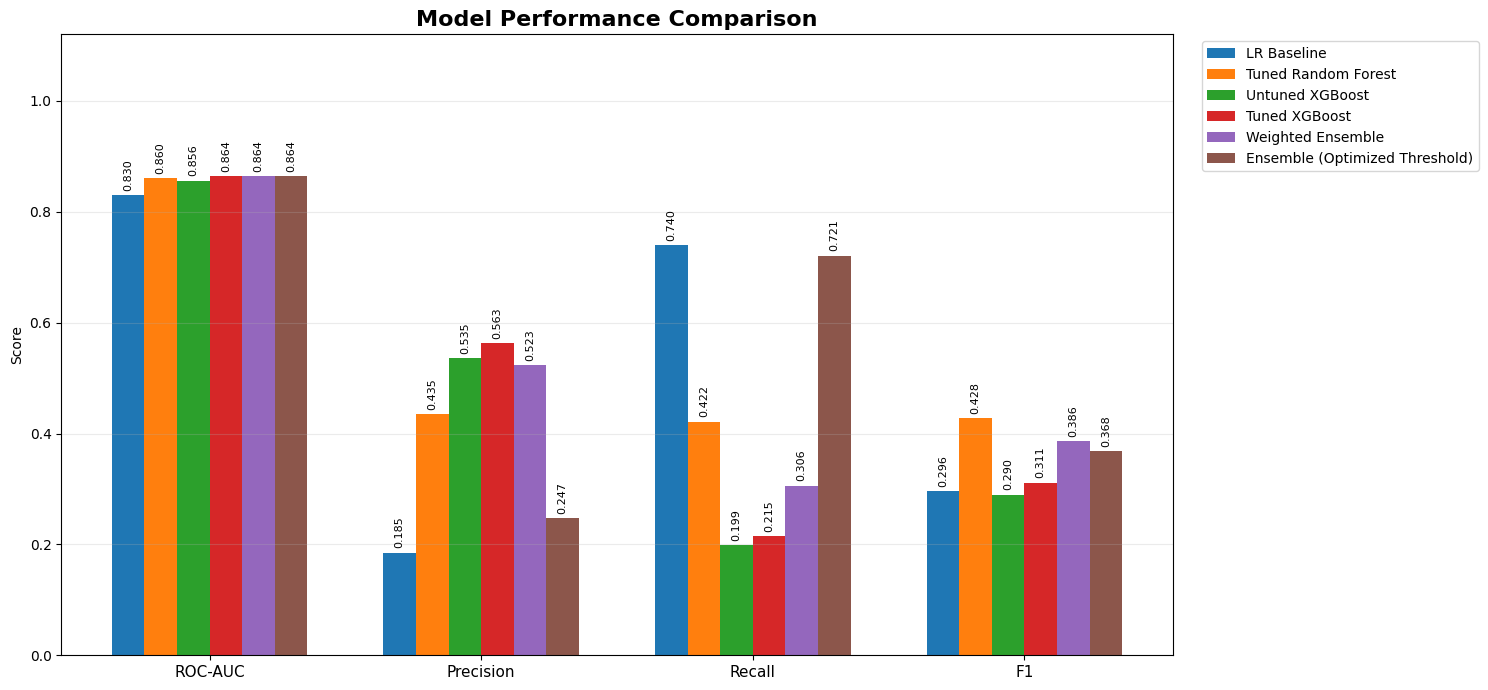

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['ROC-AUC', 'Precision', 'Recall', 'F1']

models = comparison_df.index.tolist()

x = np.arange(len(metrics))
width = 0.12

plt.figure(figsize=(15, 7))

for i, model in enumerate(models):

    values = comparison_df.loc[model, metrics].values

    bars = plt.bar(
        x + (i - len(models)/2 + 0.5) * width,
        values,
        width,
        label=model
    )

    for bar in bars:
        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.008,
            f'{height:.3f}',
            ha='center',
            va='bottom',
            fontsize=8,
            rotation=90
        )

plt.xticks(x, metrics, fontsize=11)
plt.ylabel('Score')
plt.title(
    'Model Performance Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.ylim(0, 1.12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

**6.2 ROC curves – All models**

In [ ]:
model_probabilities = {
    'LR Baseline': y_test_prob_lr,
    'Random Forest': y_test_prob_rf,
    'Untuned XGBoost': y_test_prob_xgb,
    'Tuned XGBoost': y_test_prob_tuned,
    'Weighted Ensemble': y_test_probs
}

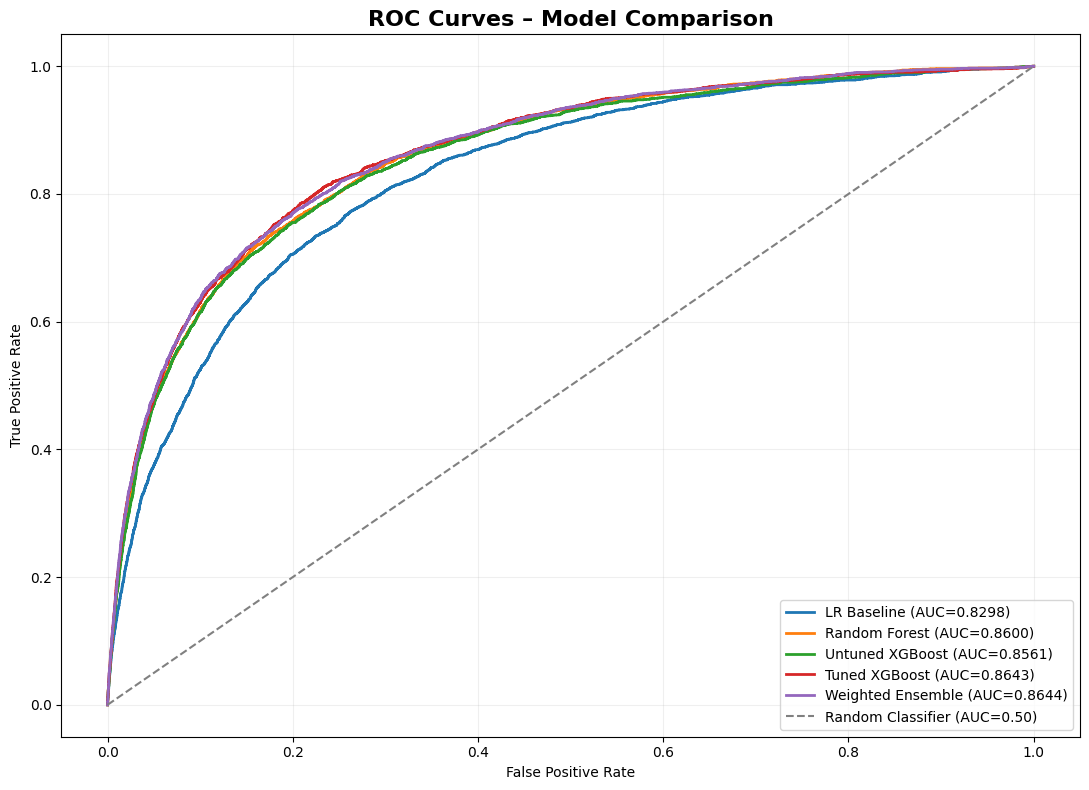

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(11, 8))

for model, probabilities in model_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{model} (AUC={auc:.4f})'
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier (AUC=0.50)'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(
    'ROC Curves – Model Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.legend(loc='lower right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**6.3 Precision–Recall curves – All model**

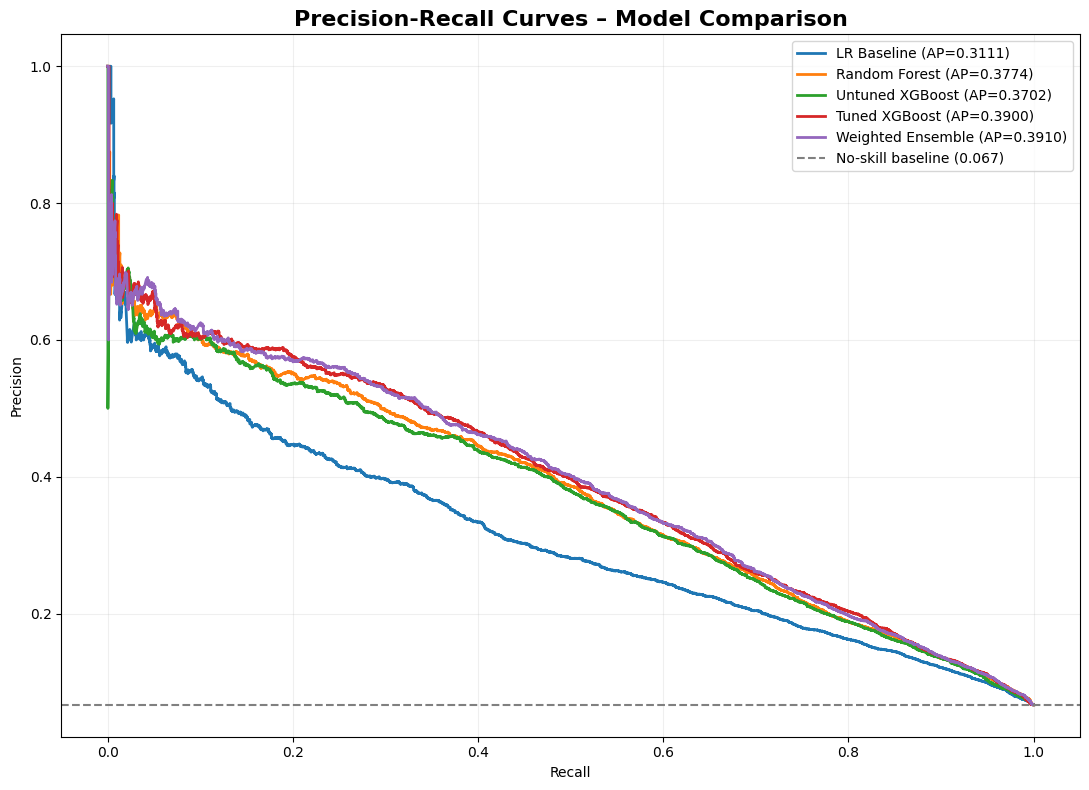

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(11, 8))

for model, probabilities in model_probabilities.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probabilities
    )

    ap = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f'{model} (AP={ap:.4f})'
    )

# No-skill baseline
baseline = np.mean(y_test)

plt.axhline(
    baseline,
    color='gray',
    linestyle='--',
    label=f'No-skill baseline ({baseline:.3f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')

plt.title(
    'Precision-Recall Curves – Model Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.legend(loc='upper right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**6.4 Multi-metric radar chart**

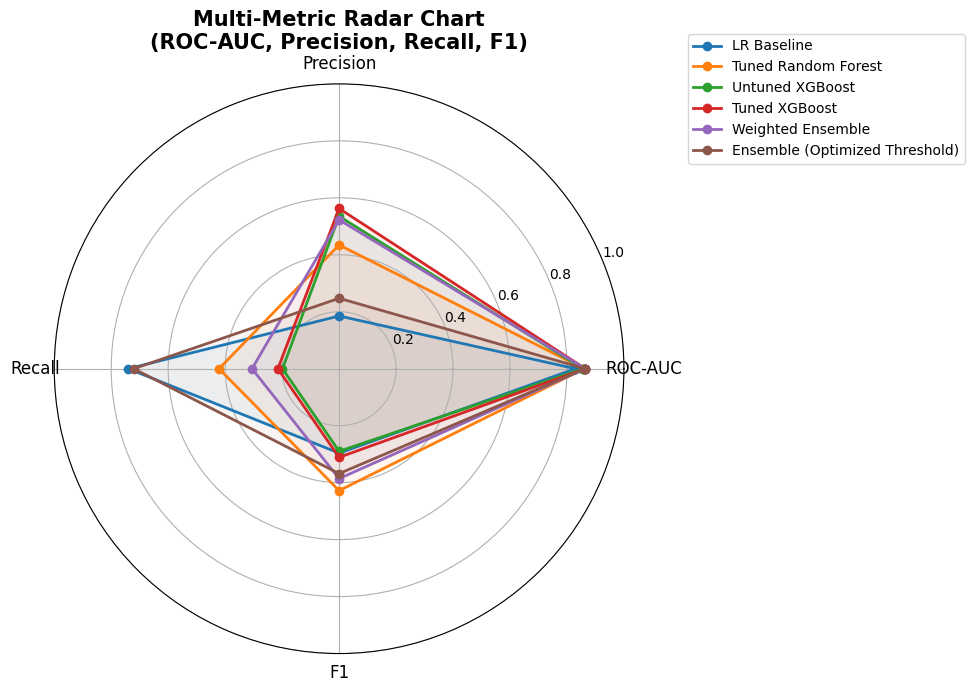

In [ ]:
from math import pi

radar_metrics = ['ROC-AUC', 'Precision', 'Recall', 'F1']

labels = radar_metrics
num_vars = len(labels)

angles = np.linspace(
    0, 2 * np.pi,
    num_vars,
    endpoint=False
).tolist()

angles += angles[:1]

fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw=dict(polar=True)
)

for model in comparison_df.index:

    values = comparison_df.loc[
        model, radar_metrics
    ].tolist()

    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        marker='o',
        label=model
    )

    ax.fill(
        angles,
        values,
        alpha=0.06
    )

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=12)

ax.set_ylim(0, 1)

ax.set_title(
    'Multi-Metric Radar Chart\n(ROC-AUC, Precision, Recall, F1)',
    fontsize=15,
    fontweight='bold',
    pad=25
)

ax.legend(
    loc='upper left',
    bbox_to_anchor=(1.1, 1.1)
)

plt.tight_layout()
plt.show()

**6.5 Performance heatmap**

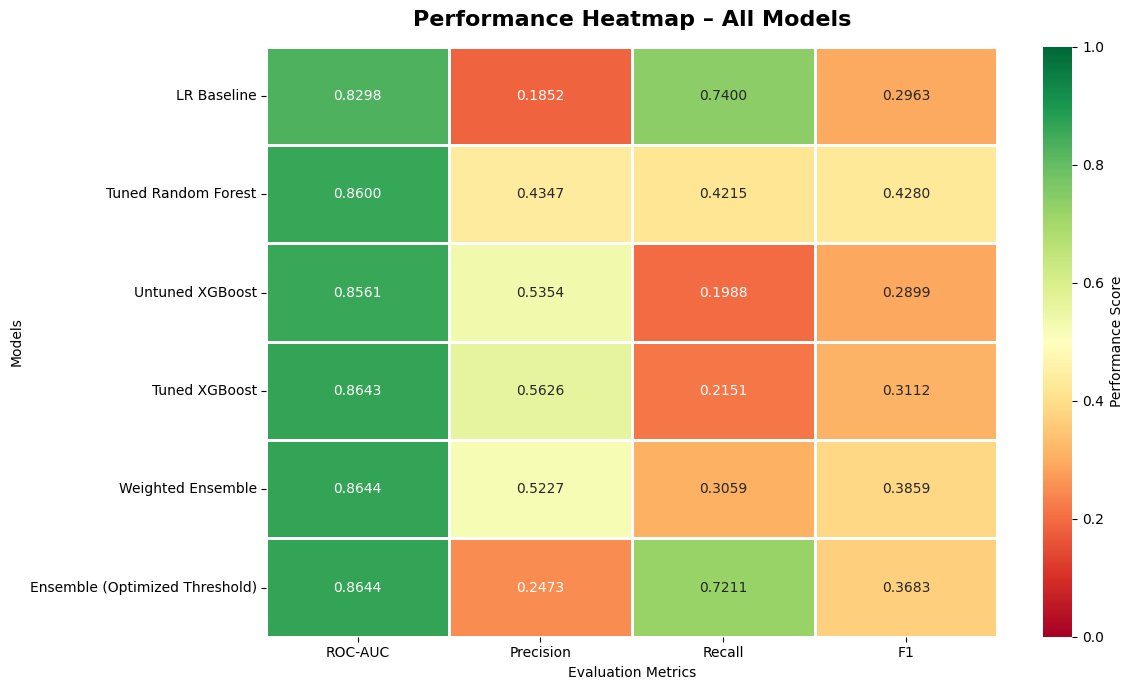

In [ ]:
import seaborn as sns

heatmap_metrics = ['ROC-AUC', 'Precision', 'Recall', 'F1']

heatmap_data = comparison_df[heatmap_metrics]

plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.4f',
    cmap='RdYlGn',
    linewidths=1,
    vmin=0,
    vmax=1,
    cbar_kws={
        'label': 'Performance Score'
    }
)

plt.title(
    'Performance Heatmap – All Models',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Evaluation Metrics')
plt.ylabel('Models')

plt.tight_layout()
plt.show()

**6.6 Confusion matrix comparison**

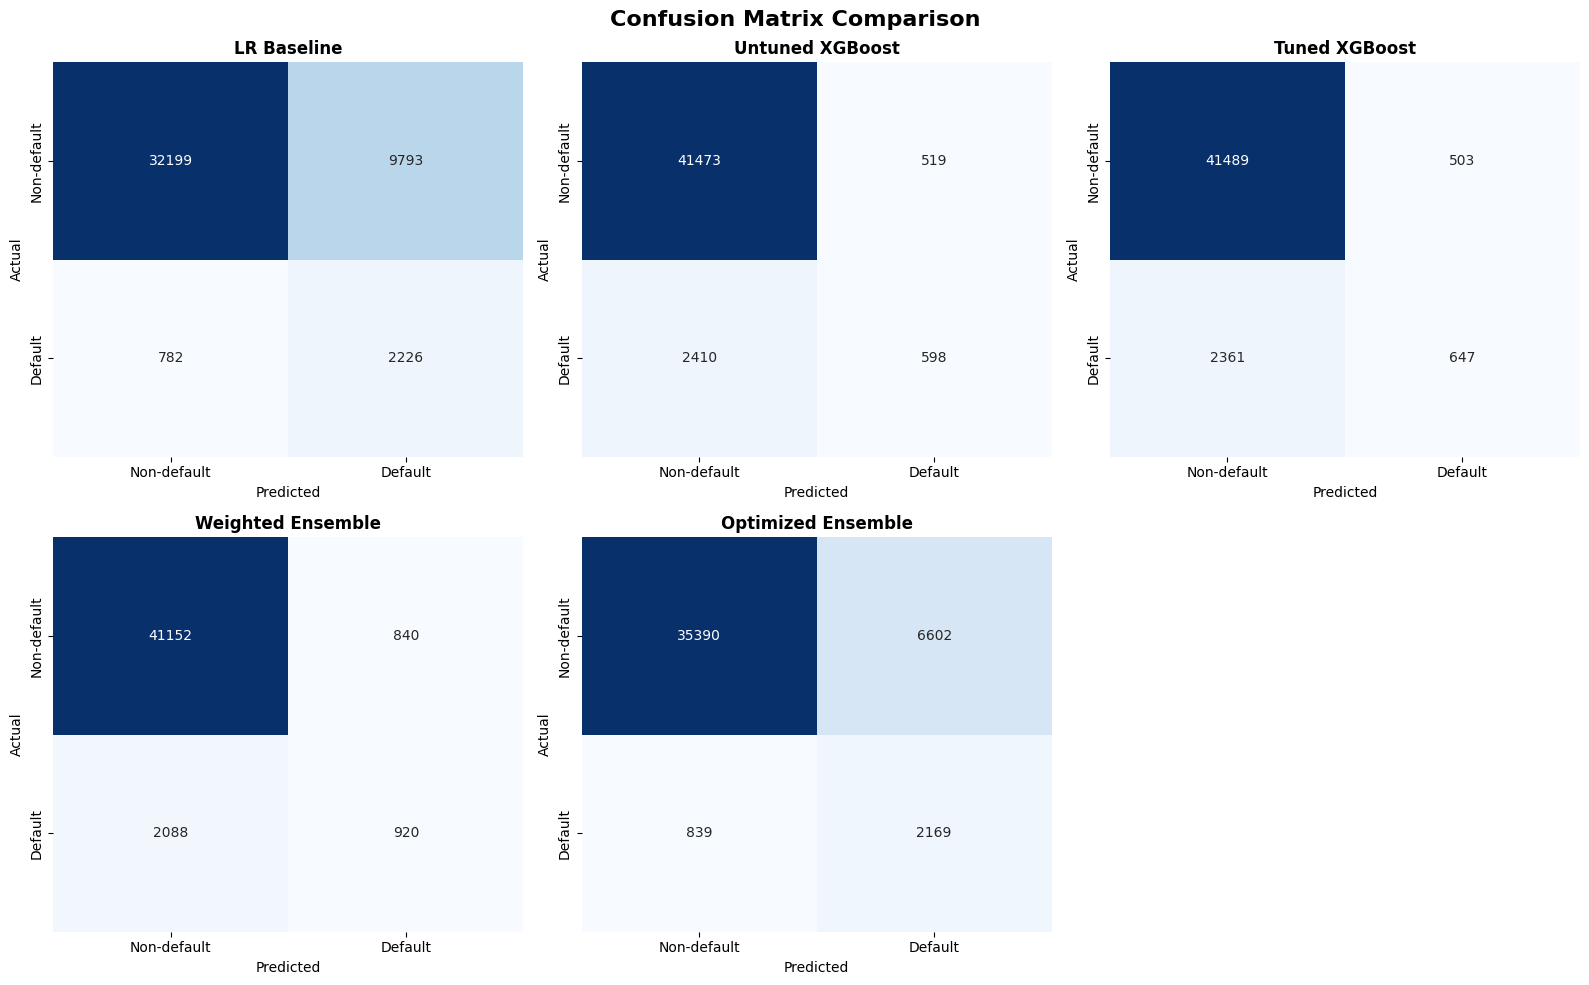

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

confusion_matrices = {
    'LR Baseline': Pipeline_A_results[dataset_name],
    'Untuned XGBoost': results_dict['Untuned XGBoost']['Test'],
    'Tuned XGBoost': results_dict['Tuned XGBoost']['Test'],
    'Weighted Ensemble': results_dict['Weighted Ensemble']['Test'],
    'Optimized Ensemble': results_dict[
        'Weighted Ensemble (Optimized Threshold)'
    ]['Test']
}

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

for ax, (model, result) in zip(
    axes.flat,
    confusion_matrices.items()
):

    if model == 'LR Baseline':
        cm = np.array([
            [result['TN'], result['FP']],
            [result['FN'], result['TP']]
        ])
    else:
        cm = result['Confusion Matrix']

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        cbar=False
    )

    ax.set_title(model, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticklabels(['Non-default', 'Default'])
    ax.set_yticklabels(['Non-default', 'Default'])

# Hide unused subplot
axes.flat[-1].axis('off')

plt.suptitle(
    'Confusion Matrix Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import joblib
import pandas as pd

path = '/content/drive/MyDrive/'

X_train = joblib.load(path + 'X_train.pkl')
X_test  = joblib.load(path + 'X_test.pkl')
y_train = joblib.load(path + 'y_train.pkl')
y_test  = joblib.load(path + 'y_test.pkl')

# your model
best_ensemble = joblib.load(path + 'credit_risk_model.pkl')

SEED = 42  # use the same value you trained with

Mounted at /content/drive


#**Section 7. SHAP Explainability – Weighted Ensemble Model (XGBoost + Random Forest)**

In [2]:
import shap
import numpy as np
import pandas as pd

# Background dataset: representative training observations
background = X_train.sample(
    n=100,
    random_state=SEED
)

# Observations to explain
X_explain = X_test.sample(
    n=100,
    random_state=SEED
)

In [6]:
bundle = best_ensemble
best_ensemble = bundle['model']
threshold = bundle['threshold']
features = bundle['features']

print(type(best_ensemble))
print(threshold, len(features))

<class 'sklearn.ensemble._voting.VotingClassifier'>
0.1833652866853839 10


In [7]:
def ensemble_predict(X):
    X = pd.DataFrame(X, columns=X_train.columns)
    return best_ensemble.predict_proba(X[features])[:, 1]


explainer_ensemble = shap.Explainer(
    ensemble_predict,
    background,
    algorithm="permutation"
)

In [8]:
shap_values_ensemble = explainer_ensemble(
    X_explain,
    max_evals=10 * (2 * X_train.shape[1] + 1)
)

PermutationExplainer explainer: 101it [01:41,  1.12s/it]


**7.1 - SHAP Beeswarm Plot – Feature Impact and Direction**

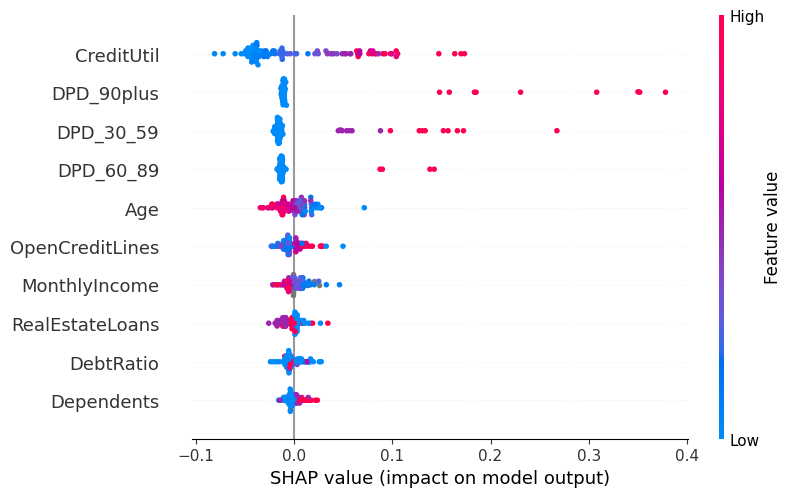

In [9]:
shap.plots.beeswarm(
    shap_values_ensemble,
    max_display=10
)

* CreditUtil is the most influential feature in predicting credit default. Higher credit utilization generally pushes the model's predicted default probability upward, while lower utilization tends to reduce it.



* DPD_90plus, DPD_30_59, and DPD_60_89 are the next most influential features. Higher delinquency counts have a strong positive impact on predicted default probability. Most observations have zero delinquency, but observations with positive delinquency counts can substantially increase predicted risk.



* Age shows a predominantly negative relationship with default risk: higher ages generally reduce predicted default probability, whereas younger borrowers tend to have higher predicted risk.



* MonthlyIncome generally shows that higher income reduces predicted default probability.



* OpenCreditLines, RealEstateLoans, DebtRatio, and Dependents have comparatively smaller impacts on the model's predictions.

**7.2 - SHAP Feature Importance – Mean Absolute SHAP Values**

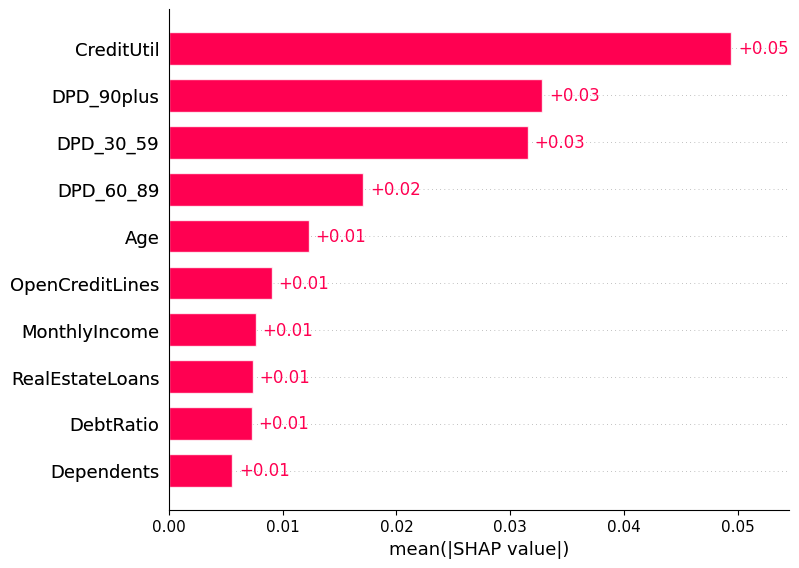

In [10]:
shap.plots.bar(
    shap_values_ensemble,
    max_display=10
)

* CreditUtil has the highest average contribution, with a mean absolute SHAP value of approximately 0.05.



* The three delinquency variables collectively represent a substantial portion of the model's explanatory importance.



* Credit utilization is particularly influential, followed by borrowers' history of missed payments.



* Age and OpenCreditLines have moderate contributions compared with the leading features.



* Dependents has the smallest average contribution among the ten features.

**7.3 - SHAP Waterfall Plot – Individual Borrower Prediction**

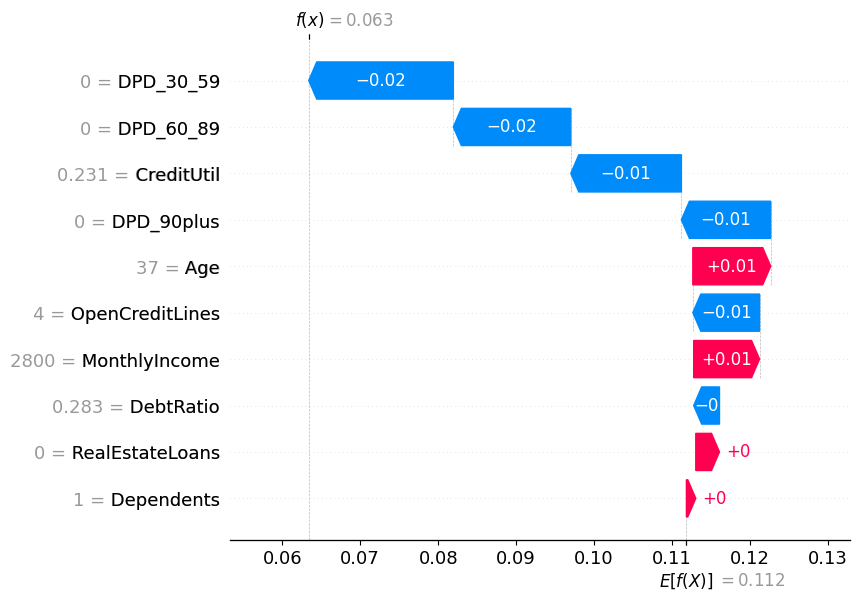

In [11]:
shap.plots.waterfall(
    shap_values_ensemble[0],
    max_display=10
)

* The model's expected output (baseline prediction) is approximately 0.112 (11.2%).



* The individual borrower's predicted default probability is approximately 0.063 (6.3%).



Several features reduce the predicted default probability:
* DPD_30_59 = 0 contributes approximately -0.02.
- DPD_60_89 = 0 contributes approximately -0.02.
- CreditUtil = 0.231 contributes approximately -0.01.
- DPD_90plus = 0 contributes approximately -0.01.
- OpenCreditLines = 4 contributes approximately -0.01.



Age = 37 and MonthlyIncome = 2,800 contribute approximately +0.01 each, slightly increasing the predicted default probability.



DebtRatio, RealEstateLoans, and Dependents have relatively small contributions for this particular observation.

**7.4 - SHAP Analysis Findings & Inference**

The SHAP analysis provides both global and individual-level explanations of the weighted XGBoost–Random Forest ensemble.

Three major findings emerge:
1. Credit utilization is the strongest predictor: CreditUtil consistently ranks first in both global SHAP visualizations, indicating its substantial influence on the ensemble's predictions.

2. Delinquency history is highly influential: DPD_90plus, DPD_30_59, and DPD_60_89 collectively contribute significantly to the model's predictive behavior. Borrowers with previous delinquencies tend to receive higher predicted default probabilities.

3. Individual predictions are explainable: The waterfall plot demonstrates how different borrower characteristics combine to produce an individual default probability, making the model's predictions more interpretable.
Overall, the SHAP results indicate that the ensemble primarily relies on credit utilization and repayment history when assessing default risk. The consistency between global feature importance and individual-level explanations provides additional insight into the model's decision-making process.

Overall, the SHAP results indicate that the ensemble primarily relies on credit utilization and repayment history when assessing default risk. The consistency between global feature importance and individual-level explanations provides additional insight into the model's decision-making process.